# Гидродинамическая система

In [1]:
import numpy as np

class HydrodynamicsSystem:
    def __init__(self, n, L_total=300.0, M=0.016, T=293.15, theta=0.1, p_in=5e6, v_in=10.0, S=None):
        self.n = n
        self.L_total = L_total
        
        R = 8.314
        self.K = M / (R * T)
        self.g = 9.81
        self.sin_theta = np.sin(theta)
        
        self.p_in = p_in
        self.v_in = v_in
        
        self.x_nodes = np.linspace(0, L_total, n + 1)
        self.dx = L_total / n
        
        if S is None:
            self.S = np.zeros(n)
        else:
            self.S = np.array(S, dtype=float)
            
        self.size = 2 * n + 3  

    def r_sys(self, vec):
        F = np.zeros(self.size)
        n = self.n
        
        p = vec[:n+2]
        v = vec[n+2:]
        
        F[0] = self.K * p[1] * v[1] - self.K * p[0] * v[0] - self.S[0]
        for i in range(2, n + 1):
            idx = i - 1
            F[idx] = self.K * p[i] * v[i] - self.K * p[i-1] * v[i-1] - self.S[idx]
            
        F[n] = p[0] - p[1] - self.K * p[0] * self.g * self.sin_theta * (self.dx / 2)
        
        for i in range(1, n):
            idx = n + i
            rho_left = self.K * (p[i-1] + p[i]) / 2 if i > 1 else self.K * p[0]
            rho_right = self.K * (p[i] + p[i+1]) / 2
            
            F[idx] = (rho_right * v[i]**2 - rho_left * v[i-1]**2 + 
                      (p[i+1] - p[i]) + 
                      rho_right * self.g * self.sin_theta * self.dx)
            
        rho_n_minus_half = self.K * (p[n-1] + p[n]) / 2
        F[2*n] = (self.K * p[n+1] * v[n]**2 - rho_n_minus_half * v[n-1]**2 + 
                  (p[n+1] - p[n]) + 
                  self.K * p[n+1] * self.g * self.sin_theta * (self.dx / 2))
        
        F[2*n + 1] = p[0] - self.p_in
        F[2*n + 2] = v[0] - self.v_in
        
        return F

    def J_sys(self, vec):
        J = np.zeros((self.size, self.size))
        n = self.n
        
        p = vec[:n+2]
        v = vec[n+2:]
        
        v_offset = n + 2
        
        J[0, 0] = -self.K * v[0]
        J[0, 1] = self.K * v[1]
        J[0, v_offset + 0] = -self.K * p[0]
        J[0, v_offset + 1] = self.K * p[1]
        for i in range(2, n + 1):
            idx = i - 1
            J[idx, i-1] = -self.K * v[i-1]
            J[idx, i] = self.K * v[i]
            J[idx, v_offset + i - 1] = -self.K * p[i-1]
            J[idx, v_offset + i] = self.K * p[i]

        J[n, 0] = 1.0 - self.K * self.g * self.sin_theta * (self.dx / 2)
        J[n, 1] = -1.0
        
        for i in range(1, n):
            idx = n + i
            if i == 1:
                J[idx, 0] = -self.K * v[0]**2 
            else:
                J[idx, i-1] = -0.5 * self.K * v[i-1]**2
                
            J[idx, i] = 0.5 * self.K * v[i]**2 - (0.5 * self.K * v[i-1]**2 if i > 1 else 0.0) - 1.0 + 0.5 * self.K * self.g * self.sin_theta * self.dx
            J[idx, i+1] = 0.5 * self.K * v[i]**2 + 1.0 + 0.5 * self.K * self.g * self.sin_theta * self.dx
            
            J[idx, v_offset + i - 1] = -2.0 * self.K * p[0] * v[0] if i == 1 else -self.K * (p[i-1] + p[i]) * v[i-1]
            J[idx, v_offset + i] = self.K * (p[i] + p[i+1]) * v[i]

        J[2*n, n-1] = -0.5 * self.K * v[n-1]**2
        J[2*n, n] = -0.5 * self.K * v[n-1]**2 - 1.0
        J[2*n, n+1] = self.K * v[n]**2 + 1.0 + self.K * self.g * self.sin_theta * (self.dx / 2)
        J[2*n, v_offset + n - 1] = -self.K * (p[n-1] + p[n]) * v[n-1]
        J[2*n, v_offset + n] = 2.0 * self.K * p[n+1] * v[n]

        J[2*n + 1, 0] = 1.0#dp0
        J[2*n + 2, v_offset + 0] = 1.0#dv0
        
        return J

    def f_sys(self, vec):
        rx = self.r_sys(vec)
        return 0.5 * np.dot(rx, rx)

    def grad_f_sys(self, vec):
        return self.J_sys(vec).T @ self.r_sys(vec)

    def hess_f_sys(self, vec):
        Jx = self.J_sys(vec)
        return Jx.T @ Jx


# Доглег для решения систем

In [2]:
import numpy as np

def dogleg_sys_minimization_history(F_vector, jac_matrix, x0, f_scalar=None, initial_delta=1.0, max_delta=1e+6, eta=0.15, tol=1e-6, max_iter=1000):
    x = np.array(x0, dtype=float)
    delta = initial_delta
    
    x_history = [x.copy()]
    delta_history = []
    p_norm_history = []
    
    if f_scalar is None:
        f_scalar = lambda vec: 0.5 * np.dot(F_vector(vec), F_vector(vec))
        
    for k in range(max_iter):
        F = F_vector(x)
        J = jac_matrix(x)
        
        current_loss = f_scalar(x)
        g = J.T @ F
        
        if np.linalg.norm(g) < tol:
            print(f"Dogleg Sys success at iter {k}")
            break
            
        g_hat = J @ g
        norm_g = np.linalg.norm(g)
        norm_g_hat = np.linalg.norm(g_hat)
        
        if norm_g_hat == 0:
            alpha = delta / norm_g if norm_g > 0 else 0.0
        else:
            alpha = (norm_g ** 2) / (norm_g_hat ** 2)
        p_C = -alpha * g
        norm_p_C = np.linalg.norm(p_C)
        
        try:
            p_N = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            p_N = np.linalg.solve(J + 1e-5 * np.eye(len(x)), -F)
        norm_p_N = np.linalg.norm(p_N)
        
        v = p_N - p_C
        a = np.dot(v, v)
        b = 2 * np.dot(p_C, v)
        
        step_accepted = False
        while not step_accepted:
            if norm_p_N <= delta:
                p_d = p_N
            elif norm_p_C >= delta:
                p_d = (delta / norm_p_C) * p_C
            else:
                c = np.dot(p_C, p_C) - delta**2
                discriminant = b**2 - 4 * a * c
                beta = (-b + np.sqrt(max(0.0, discriminant))) / (2 * a)
                p_d = p_C + beta * v
                
            norm_p_d = np.linalg.norm(p_d)
            
            actual_reduction = current_loss - f_scalar(x + p_d)
            
            J_pd = J @ p_d
            predicted_reduction = -np.dot(g, p_d) - 0.5 * np.dot(J_pd, J_pd)
            
            rho = actual_reduction / predicted_reduction if predicted_reduction > 0 else 0.0
            
            # обновление точки
            if rho > eta:
                x = x + p_d
                p_norm_history.append(norm_p_d)
                delta_history.append(delta) #записываем дельту, с которой был принят шаг
                step_accepted = True
            else:
                step_accepted = False

            # обновление радиуса delta
            if rho < 0.25:
                delta = 0.25 * delta
            elif rho > 0.75 and norm_p_d >= delta - 1e-12:
                delta = min(2.0 * delta, max_delta)
            # в остальных случаях delta не меняется

            if not step_accepted and delta < 1e-25:
                break

        x_history.append(x.copy())
        
        if delta < 1e-25:
            print(f"Dogleg stopped: delta collapsed at iter {k}")
            break
            
        if k == max_iter - 1:
            print("Dogleg iteration exceed")
            
    return x, np.array(x_history), np.array(delta_history), np.array(p_norm_history)


# Море-Соренсон для решения Систем

In [3]:
import numpy as np
import scipy.linalg as la

def solve_exact_subproblem_sys(g, H, delta, lam_old=0.0, tol_inner=1e-4, max_inner=100):
    n = len(g)
    
    if lam_old == 0.0:
        try:
            L = la.cholesky(H, lower=True)
            p = la.cho_solve((L, True), -g)
            norm_p = np.linalg.norm(p)
            
            if norm_p <= delta:
                return p, 0.0
        except la.LinAlgError:
            p, _, _, _ = np.linalg.lstsq(H, -g, rcond=1e-12)
            norm_p = np.linalg.norm(p)
            if norm_p <= delta:
                return p, 0.0
                
        q = la.solve_triangular(L, p, lower=True, trans=0)
        norm_q = np.linalg.norm(q)
        lam = ((norm_p - delta) / delta) * (norm_p**2 / norm_q**2)
    else:
        lam = lam_old * 4.0 

    lam = max(1e-12, lam)

    for _ in range(max_inner):
        H_lam = H + lam * np.eye(n)
        
        L = la.cholesky(H_lam, lower=True)
        p = la.cho_solve((L, True), -g)
        norm_p = np.linalg.norm(p)
        
        if abs(norm_p - delta) <= tol_inner * delta:
            return p, lam
            
        q = la.solve_triangular(L, p, lower=True, trans=0)
        norm_q = np.linalg.norm(q)
        
        lam_new = lam + ((norm_p - delta) / delta) * (norm_p**2 / norm_q**2)
        lam = max(1e-12, lam_new)
            
    return p, lam

def exact_tr_sys_minimization_history(F_vector, jac_matrix, x0, f_scalar=None, initial_delta=1.0, max_delta=1e+6, eta=0.15, tol=1e-6, max_iter=1000):
    x = np.array(x0, dtype=float)
    delta = initial_delta
    
    x_history = [x.copy()]
    delta_history = []
    p_norm_history = []
    
    if f_scalar is None:
        f_scalar = lambda vec: 0.5 * np.dot(F_vector(vec), F_vector(vec))
        
    for k in range(max_iter):
        F = F_vector(x)
        J = jac_matrix(x)
        
        current_loss = f_scalar(x)
        g = J.T @ F         
        
        if np.linalg.norm(g) < tol:
            print(f"Exact TR Sys success at iter {k}")
            break
        
        H = J.T @ J         
            
        current_lam = 0.0 
        
        step_accepted = False
        while not step_accepted:
            p, current_lam = solve_exact_subproblem_sys(g, H, delta, lam_old=current_lam)
            norm_p = np.linalg.norm(p)
            
            actual_reduction = current_loss - f_scalar(x + p)
            
            J_p = J @ p
            predicted_reduction = -np.dot(g, p) - 0.5 * np.dot(J_p, J_p)
            
            rho = actual_reduction / predicted_reduction if predicted_reduction > 0 else 0.0
            
        #     if rho > eta:
        #         x = x + p
        #         p_norm_history.append(norm_p)
        #         step_accepted = True
                
        #         if rho > 0.75 and norm_p >= delta - 1e-12:
        #             delta = min(2.0 * delta, max_delta)
        #     else:
        #         delta = 0.25 * delta
        #         if delta < 1e-25:
        #             p_norm_history.append(norm_p)
        #             break
                    
        # x_history.append(x.copy())
        # delta_history.append(delta) 
        
        # if delta < 1e-25:
        #     print(f"Exact TR stopped: delta collapsed at iter {k}")
        #     break

            if rho > eta:
                x = x + p
                p_norm_history.append(norm_p)
                delta_history.append(delta)
                step_accepted = True
            else:
                step_accepted = False

            if rho < 0.25:
                delta = 0.25 * delta
            elif rho > 0.75 and norm_p >= delta - 1e-12:
                delta = min(2.0 * delta, max_delta)

            if not step_accepted and delta < 1e-25:
                break

        x_history.append(x.copy())
        
        if delta < 1e-25:
            print(f"Exact TR stopped: delta collapsed at iter {k}")
            break

        if k == max_iter - 1:
            print("Exact TR iteration exceed")
                
    return x, np.array(x_history), np.array(delta_history), np.array(p_norm_history)


# Адаптивный Ньютон для решения систем

In [4]:
import numpy as np

def adaptive_newton_sys_minimization_history(F_vector, jac_matrix, x0, f_scalar=None, initial_delta=1.0, max_delta=1e+6, eta=0.15, tol=1e-6, max_iter=1000):
    x = np.array(x0, dtype=float)
    delta = initial_delta
    
    x_history = [x.copy()]
    delta_history = []
    p_norm_history = []
    
    if f_scalar is None:
        f_scalar = lambda vec: 0.5 * np.dot(F_vector(vec), F_vector(vec))
        
    for k in range(max_iter):
        F = F_vector(x)
        J = jac_matrix(x)
        
        current_loss = f_scalar(x)
        g = J.T @ F 
        
        if np.linalg.norm(g) < tol:
            print(f"Adaptive Newton Sys success at iter {k}")
            break
            
        try:
            p_N = np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            p_N = np.linalg.solve(J + 1e-5 * np.eye(len(x)), -F)
            
        norm_p_N = np.linalg.norm(p_N)
        
        step_accepted = False
        while not step_accepted:
            alpha = min(1.0, delta / norm_p_N) if norm_p_N > 0 else 1.0
            p = alpha * p_N
            norm_p = np.linalg.norm(p)
            
            actual_reduction = current_loss - f_scalar(x + p)
            
            J_p = J @ p
            predicted_reduction = -np.dot(g, p) - 0.5 * np.dot(J_p, J_p)
            
            rho = actual_reduction / predicted_reduction if predicted_reduction > 0 else 0.0
            
        #     if rho > eta:
        #         x = x + p
        #         p_norm_history.append(norm_p)
        #         step_accepted = True
                
        #         if rho > 0.75 and norm_p >= delta - 1e-12:
        #             delta = min(2.0 * delta, max_delta)
        #     else:
        #         delta = 0.25 * delta
                
        #         if delta < 1e-25:
        #             p_norm_history.append(norm_p)
        #             break
                    
        # x_history.append(x.copy())
        # delta_history.append(delta)
        
        # if delta < 1e-25:
        #     print(f"Adaptive Newton stopped: delta collapsed at iter {k}")
        #     break
            
        # if k == max_iter - 1:
        #     print("Adaptive Newton iteration exceed")

        
            if rho > eta:
                x = x + p
                p_norm_history.append(norm_p)
                delta_history.append(delta) # Записываем дельту, с которой был принят шаг
                step_accepted = True
            else:
                step_accepted = False

            if rho < 0.25:
                delta = 0.25 * delta
            elif rho > 0.75 and norm_p >= delta - 1e-12:
                delta = min(2.0 * delta, max_delta)

            if not step_accepted and delta < 1e-25:
                break

        x_history.append(x.copy())
        
        if delta < 1e-25:
            print(f"Adaptive Newton stopped: delta collapsed at iter {k}")
            break

        if k == max_iter - 1:
            print("Adaptive Newton iteration exceed")
        

    return x, np.array(x_history), np.array(delta_history), np.array(p_norm_history)


# Сопряженные градиенты (Стейхуаг-Тойнт)

In [5]:
def steihaug_toint_subproblem(g, J, delta, epsilon=None, debug=False):
    cg_stats = {
        'alpha': [],
        'p': [],
        'r': [],
        'tau' : None,
        'exit_reason': None,
    }
    
    n = len(g)
    p = np.zeros(n, dtype=float)
    cg_stats['p'].append(p)
    r = g.copy()
    cg_stats['r'].append(r)
    d = -r

    if epsilon is None:
        # epsilon = min(0.5, np.sqrt(norm_g)) * norm_g
        epsilon = 1e-14

    norm_g = np.linalg.norm(g)
    if norm_g <= epsilon:
        cg_stats['exit_reason'] = 'zero_grad_at_start'
        return p, cg_stats

    def _hit_boundary(p, d, delta):
        a = np.dot(d, d)
        b = 2.0 * np.dot(p, d)
        c = np.dot(p, p) - delta * delta
        disc = max(0.0, b * b - 4.0 * a * c)
        tau = (-b + np.sqrt(disc)) / (2.0 * a)
        print(f"\t\t\ttau = {tau}")
        return p + tau * d, tau

    for _ in range(100*n):
        J_d = J @ d
        kappa = np.dot(J_d, J_d)

        #нулевая кривизна
        if kappa <= 1e-15:
            print(f"\t\tКривизна")
            cg_stats['exit_reason'] = 'zero_curvature'
            p_final, tau = _hit_boundary(p, d, delta)
            cg_stats['p'].append(p_final)
            cg_stats['tau'] = tau
            return p_final, cg_stats

        alpha = np.dot(r, r) / kappa
        cg_stats['alpha'].append(alpha)
        p_next = p + alpha * d
        cg_stats['p'].append(p_next)

        #граница области
        if np.linalg.norm(p_next) >= delta:
            print(f"\t\tОбрезание, итераций CG {_+1}/{n}")
            cg_stats['exit_reason'] = 'boundary'
            p_final, tau = _hit_boundary(p, d, delta)
            cg_stats['p'].append(p_final) 
            cg_stats['tau'] = tau 
            return p_final, cg_stats

        r_next = r + alpha * (J.T @ J_d)
        cg_stats['r'].append(r_next)

        #нулевая невязка
        if np.linalg.norm(r_next) < epsilon:
            print(f"\t\tr слишком мало, итераций CG {_+1}/{n}")
            cg_stats['exit_reason'] = "small_r"
            return p_next, cg_stats

        beta = np.dot(r_next, r_next) / np.dot(r, r)
        p, r, d = p_next, r_next, -r_next + beta * d

    print(f"\t\tШтатный выход из итераций CG, итераций CG {_+1}/{n}")
    cg_stats['exit_reason'] = 'max_iter'
    return p, cg_stats 


def steihaug_cg_tr_sys_minimization_history(F_vector, jac_matrix, x0, f_scalar=None, initial_delta=1.0, max_delta=1e+6, eta=0.15, tol=1e-6, max_iter=1000):
    # великий дебаг начало
    DEBUG_ITERS = [1, 2, 3, 4, 5, 6, 13, 14, 18, 24, 25, 26, 27]
    num_of_inner_iterations = [] 
    cg_stats = []
    # великий дебаг конец

    x = np.array(x0, dtype=float)
    delta = initial_delta
    
    x_history = [x.copy()]
    delta_history = []
    delta_all_history = []
    p_norm_history = []
    p_norm_all_history = []
    rho_history = [] 
    rho_all_history = [] 
    
    if f_scalar is None:
        f_scalar = lambda vec: 0.5 * np.dot(F_vector(vec), F_vector(vec))
        
    for k in range(max_iter):
        print(f"\nИтерация номер {k+1} началась:")
        F = F_vector(x)
        J = jac_matrix(x)
        
        current_loss = f_scalar(x)
        g = J.T @ F
        
        if np.linalg.norm(g) < tol:
            print(f"Steihaug-Toint success at iter {k}")
            break
            
        step_accepted = False
        p_norm_this_outer = [] 
        delta_this_outer = [] 
        rhos_this_outer = [] 
        num_of_inner_iterations_this_outer = []
        cg_stats_this_outer = []
        inner_iterations_counter = 1
        while not step_accepted:
            print(f"\tвнутренняя итерация номер {inner_iterations_counter} началась:")
            #решаем подзадачу с помощью усеченного CG
            p, cg_stat = steihaug_toint_subproblem(g, J, delta)
            num_of_inner_iterations_this_outer.append(len(cg_stat['alpha']))
            cg_stats_this_outer.append(cg_stat)
            if k + 1 in DEBUG_ITERS:
                plt.figure()
                reason_to_color = {'zero_grad_at_start' : 'yellow', 'zero_curvature' : 'red', 'boundary' : 'blue', 'small_r' : 'purple', 'max_iter' : 'green'}
                exit_reason = cg_stat['exit_reason']
                ps_inside_cg = cg_stat['p']
                m = lambda p: f_scalar(x) + np.dot(g, p) + 0.5 * np.dot(J @ p, J @ p)
                f_values_inside_cg = [f_scalar(x + p_cg) for p_cg in ps_inside_cg]
                m_values_inside_cg = [m(p_cg) for p_cg in ps_inside_cg]
                if exit_reason == 'zero_curvature' or exit_reason == 'boundary':
                    plt.plot(np.arange(len(ps_inside_cg)-1), m_values_inside_cg[:-1:], linestyle='-', marker='.', markersize=5, linewidth=1.5, label=fr'$m(p_i)$')
                    plt.plot(np.arange(len(ps_inside_cg)-1), f_values_inside_cg[:-1:], linestyle='-', marker='.', markersize=5, linewidth=1.5, label=fr'$f(p_i)$')
                    plt.plot([len(ps_inside_cg) - 3 + h for h in np.linspace(0, 1, 20)], [m((1-h) * ps_inside_cg[-3] + h * ps_inside_cg[-2]) for h in np.linspace(0, 1, 20)], color='C0', linestyle='--', linewidth=1.5)
                    plt.plot([len(ps_inside_cg) - 3 + h for h in np.linspace(0, 1, 20)], [f_scalar(x + (1-h) * ps_inside_cg[-3] + h * ps_inside_cg[-2]) for h in np.linspace(0, 1, 20)], color='C1', linestyle='--', linewidth=1.5)
                    plt.scatter(len(ps_inside_cg) - 3 + cg_stat['tau']/cg_stat['alpha'][-1], m_values_inside_cg[-1], color = reason_to_color[exit_reason], marker = 'x', s=80, linewidths=3, zorder = 5, label = exit_reason)
                    plt.scatter(len(ps_inside_cg) - 3 + cg_stat['tau']/cg_stat['alpha'][-1], f_values_inside_cg[-1], color = reason_to_color[exit_reason], marker = 'x', s=80, linewidths=3, zorder = 5)
                    plt.axvline(len(ps_inside_cg) - 3 + cg_stat['tau']/cg_stat['alpha'][-1], color = reason_to_color[exit_reason], linestyle='-', linewidth=1.0, alpha=0.4)
                else:
                    plt.plot(np.arange(len(ps_inside_cg)), m_values_inside_cg, linestyle='-', marker='.', markersize=5, linewidth=1.5, label=fr'$m(p_i)$')
                    plt.plot(np.arange(len(ps_inside_cg)), f_values_inside_cg, linestyle='-', marker='.', markersize=5, linewidth=1.5, label=fr'$f(p_i)$')                    
                    plt.scatter(len(ps_inside_cg) - 1, m_values_inside_cg[-1], color = reason_to_color[exit_reason], marker = 'x', s=80, linewidths=3, zorder = 5, label = exit_reason)
                    plt.scatter(len(ps_inside_cg) - 1, f_values_inside_cg[-1], color = reason_to_color[exit_reason], marker = 'x', s=80, linewidths=3, zorder = 5)
                    plt.axvline(len(ps_inside_cg) - 1, color = reason_to_color[exit_reason], linestyle='-', linewidth=1.0, alpha=0.4)
                print(f"\t\t\tзначение ро по CG = {(f_values_inside_cg[0] - f_values_inside_cg[-1])/(m_values_inside_cg[0] - m_values_inside_cg[-1])}")
                plt.xlabel('Номер итерации CG (i)', fontsize=10)
                # plt.yscale('log')
                plt.legend(loc='best', fontsize=12)
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.tight_layout()
                plt.title(fr"Значения f($p_i$) и m($p_i$) в CG на {inner_iterations_counter}-ой внутренней итерации {k+1}-ого шага Trust Region", fontsize=10.5, fontweight='bold', pad=12)
                # plt.show()

            norm_p = np.linalg.norm(p)
            
            actual_reduction = current_loss - f_scalar(x + p)
            
            J_p = J @ p
            predicted_reduction = -np.dot(g, p) - 0.5 * np.dot(J_p, J_p)
            
            rho = actual_reduction / predicted_reduction 
            print(f"\t\tдельта = {delta} (это дельта текущей внутренней итерации TR, то есть по ней в этой внутренней итерации обрезалось p )")
            print(f"\t\trho = {rho}")

            p_norm_this_outer.append(norm_p)
            delta_this_outer.append(delta)
            rhos_this_outer.append(rho)

            #обновление точки
            if rho > eta:
                x = x + p
                p_norm_history.append(norm_p)
                delta_history.append(delta) #записываем дельту с которой был принят шаг
                rho_history.append(rho) 
                print(f"\t\tдельта с которой принялась поправка: дельта_{k+1} = {delta} ()")
                step_accepted = True
            else:
                step_accepted = False

            #обновление delta
            if rho < 0.25:
                delta = 0.25 * delta
                print(f"\t\tна следующей внутр итерации дельта уменьшается\n")
            elif rho > 0.75 and norm_p >= delta * (1 - 1e-10):
                delta = min(2.0 * delta, max_delta)
                print(f"\t\tна следующей внутр итерации дельта увеличивается\n")
            else:
                print(f"\t\tна следующей внутр итерации дельта не меняется\n")
            # в остальных случаях delta не меняется

            if not step_accepted and delta < 1e-25:
                break

            inner_iterations_counter += 1

        x_history.append(x.copy())
        p_norm_all_history.append(p_norm_this_outer)
        delta_all_history.append(delta_this_outer)
        rho_all_history.append(rhos_this_outer)
        num_of_inner_iterations.append(num_of_inner_iterations_this_outer)
        cg_stats.append(cg_stats_this_outer)
        
        if delta < 1e-25:
            print(f"ST stopped: delta collapsed at iter {k}")
            break
            
        if k == max_iter - 1:
            print("ST iteration exceed")

    #великий дебаг картинки начало
    # print(num_of_inner_iterations)
    exit_reasons = [cg_stat['exit_reason'] for cg_stats_outer in cg_stats for cg_stat in cg_stats_outer]
    reason_to_color = {'zero_grad_at_start' : 'yellow', 'zero_curvature' : 'red', 'boundary' : 'blue', 'small_r' : 'purple', 'max_iter' : 'green'}

    plt.figure(figsize=(11, 5), dpi=300)
    num_of_inner_iterations_plot = [val for sublist in num_of_inner_iterations for val in sublist]
    x_plot = np.arange(1, len(num_of_inner_iterations_plot) + 1)
    plt.plot(x_plot, num_of_inner_iterations_plot, color='purple', linestyle='-', marker='.', markersize=5, linewidth=1.5, label=r'ST')
    plt.scatter(x_plot, num_of_inner_iterations_plot, color=[reason_to_color[reason] for reason in exit_reasons], marker = 'x', s=50, linewidths=3, zorder = 5 )
    boundaries = np.cumsum([len(r) for r in num_of_inner_iterations])
    y_max = max(num_of_inner_iterations_plot) + 2.0
    for k, b_idx in enumerate(boundaries, start=1):
        plt.axvline(b_idx, color='black', linestyle='-', linewidth=1.0, alpha=0.4)
        plt.text(b_idx-0.2, y_max, f' {k}', color='black', fontsize=9, ha='left', va='top')
    plt.xticks([])
    plt.xlabel('')
    plt.ylim(top=y_max)
    plt.title(f"Количество итераций CG внутри каждой внутренней итерации Trust Region\n", fontsize=10.5, fontweight='bold', pad=12)
    plt.ylabel('Количество итераций CG', fontsize=10)
    from matplotlib.lines import Line2D
    legend_handles = [
        Line2D([], [], marker='x', color='yellow',   linestyle='None',
                   markersize=8, markeredgewidth=2, label='нулевой градиент в начале'),
        Line2D([], [], marker='x', color='red',   linestyle='None',
               markersize=8, markeredgewidth=2, label='нулевая кривизна'),
        Line2D([], [], marker='x', color='blue',  linestyle='None',
               markersize=8, markeredgewidth=2, label='обрезка по радиусу'),
        Line2D([], [], marker='x', color='purple',  linestyle='None',
                   markersize=8, markeredgewidth=2, label='выход по малости r'),
        Line2D([], [], marker='x', color='green', linestyle='None',
               markersize=8, markeredgewidth=2, label='штатный выход из CG')]
    plt.legend(handles=legend_handles, loc='best', fontsize=8.5, ncol=2)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

    #великий дебаг картинки конец


    return x, np.array(x_history), np.array(delta_history), np.array(p_norm_history), np.array(rho_history), p_norm_all_history, delta_all_history, rho_all_history


# Тесты гидродинамической системы с методами для систем

### Неадптивная дельта0

#### n = 10

Dogleg Sys success at iter 17
Exact TR iteration exceed
Adaptive Newton Sys success at iter 16

Итерация номер 1 началась:
	внутренняя итерация номер 1 началась:
		Обрезание, итераций CG 1/23
			tau = 1.2896673507769652e-06
			значение ро по CG = 1.0089188697096165
		дельта = 1.0 (это дельта текущей внутренней итерации TR, то есть по ней в этой внутренней итерации обрезалось p )
		rho = 1.0089188697096165
		дельта с которой принялась поправка: дельта_1 = 1.0 ()
		на следующей внутр итерации дельта увеличивается


Итерация номер 2 началась:
	внутренняя итерация номер 1 началась:
		Обрезание, итераций CG 1/23
			tau = 3.3396019862295027e-06
			значение ро по CG = 0.9850983967211324
		дельта = 2.0 (это дельта текущей внутренней итерации TR, то есть по ней в этой внутренней итерации обрезалось p )
		rho = 0.9850983967211329
		дельта с которой принялась поправка: дельта_2 = 2.0 ()
		на следующей внутр итерации дельта увеличивается


Итерация номер 3 началась:
	внутренняя итерация номер 1 на

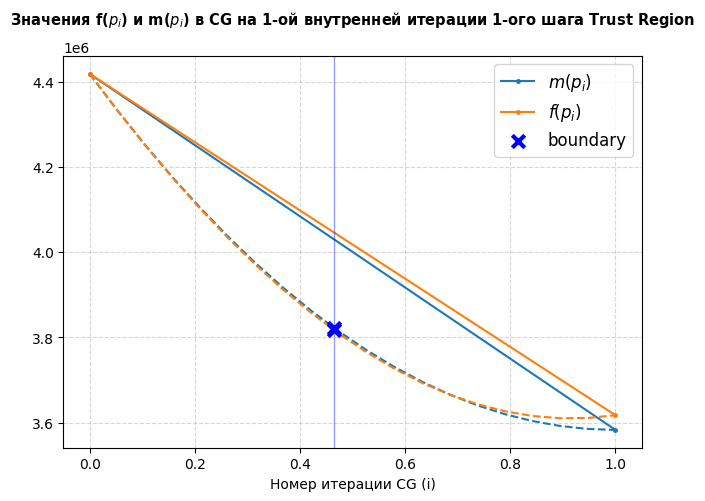

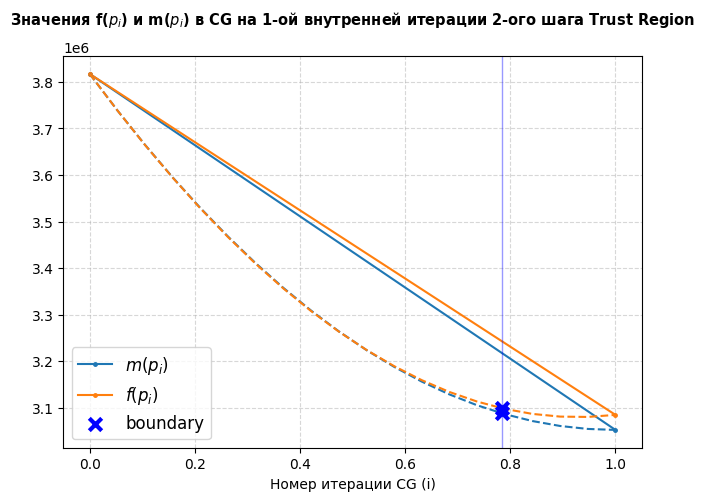

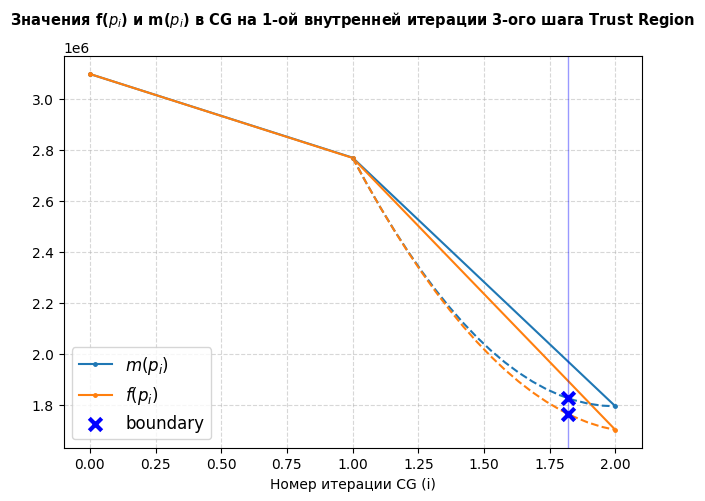

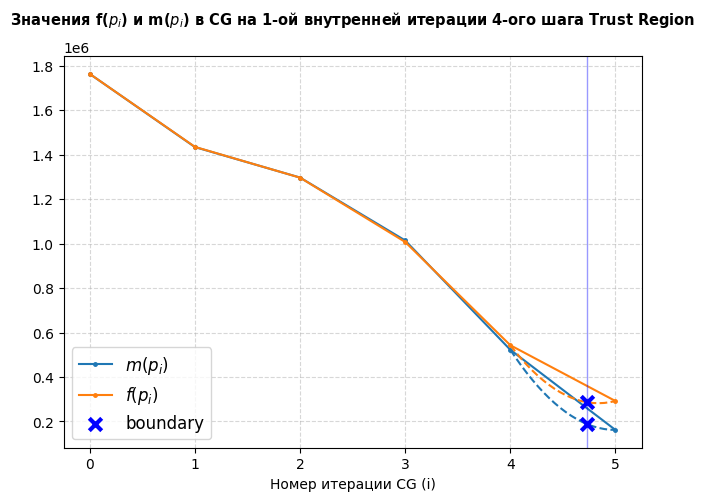

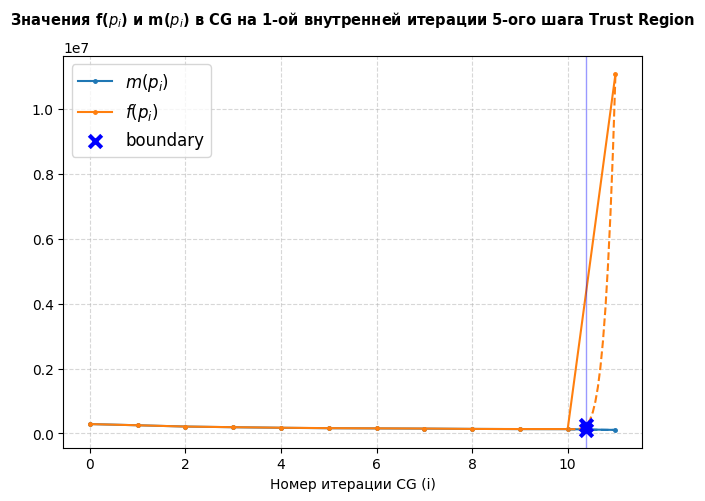

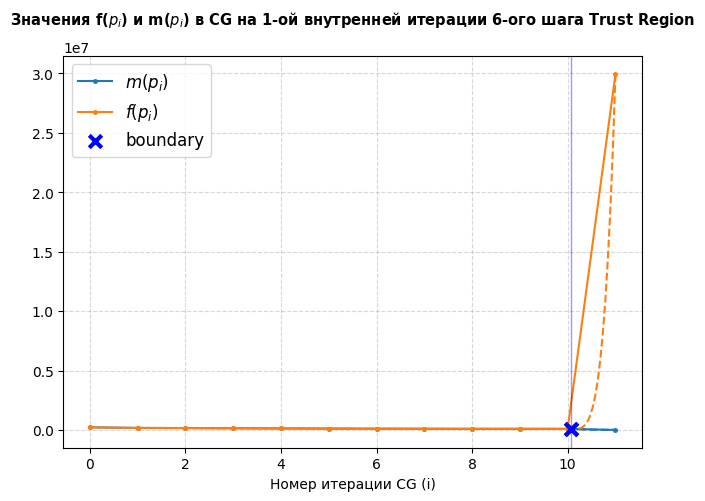

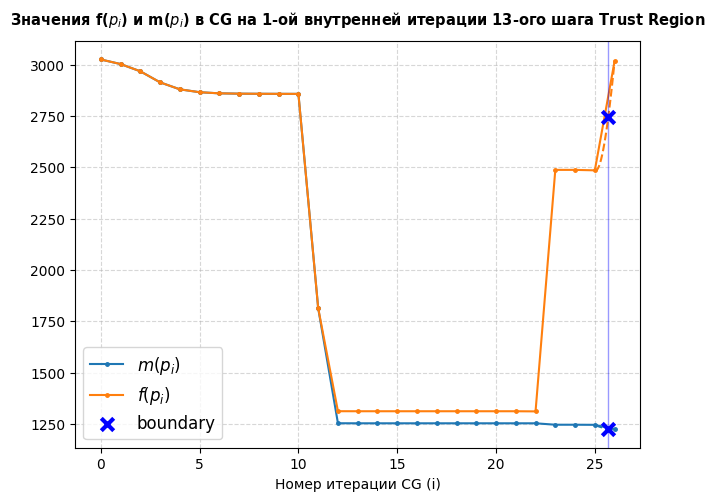

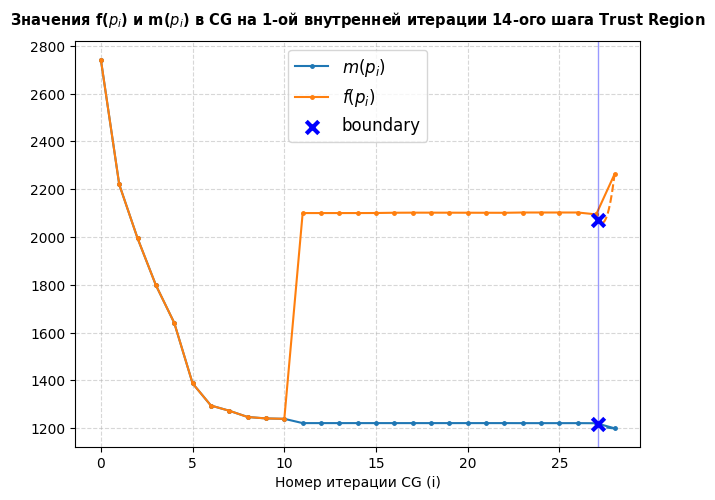

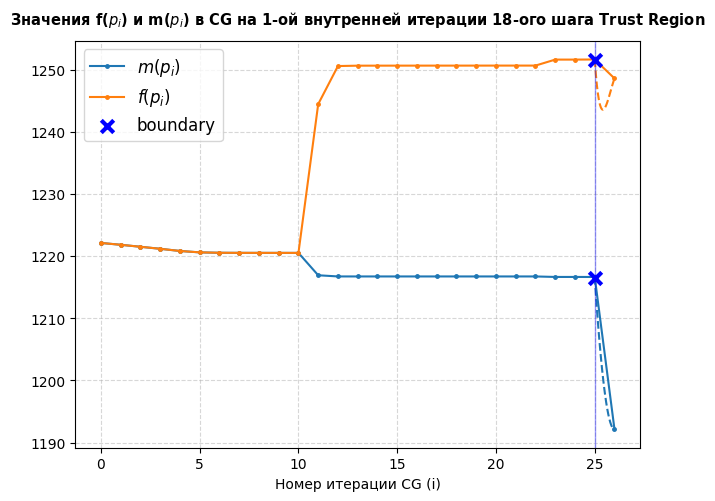

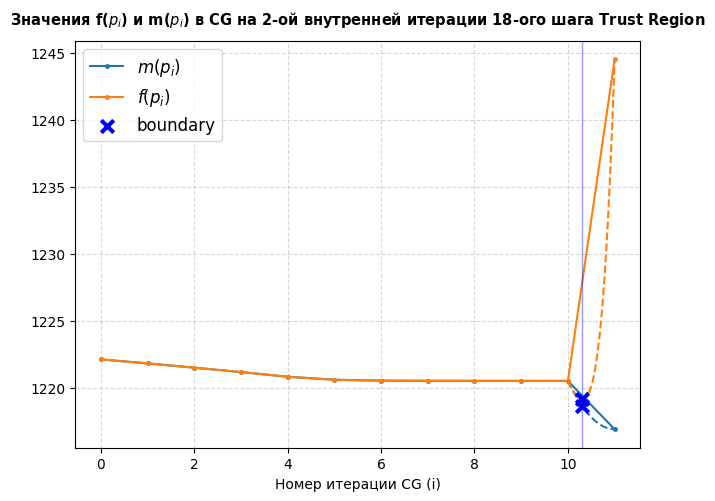

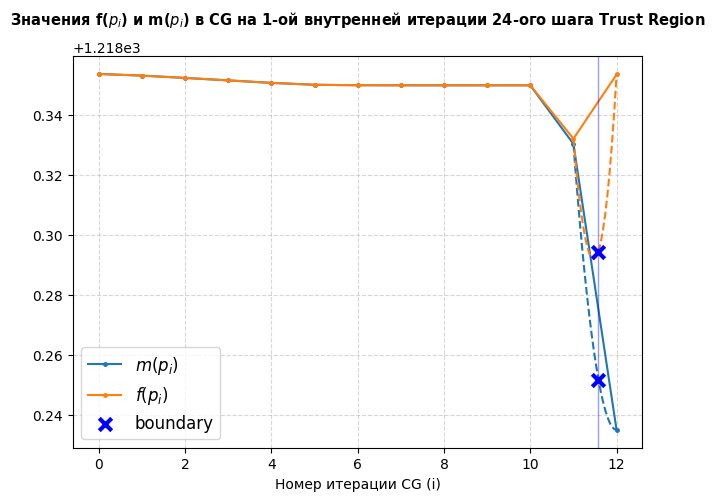

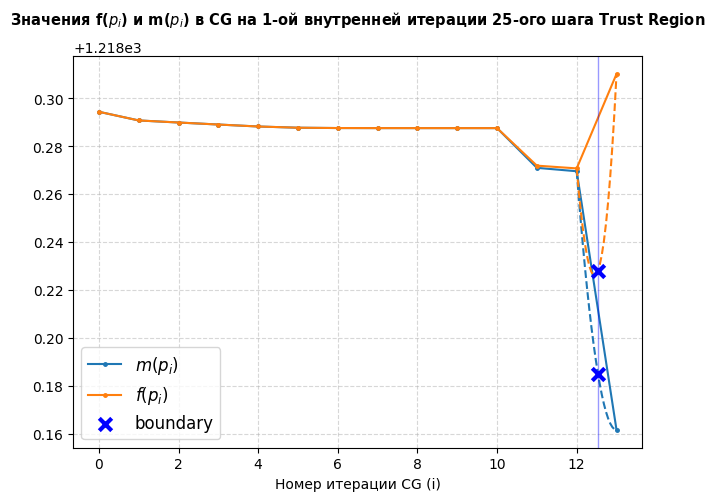

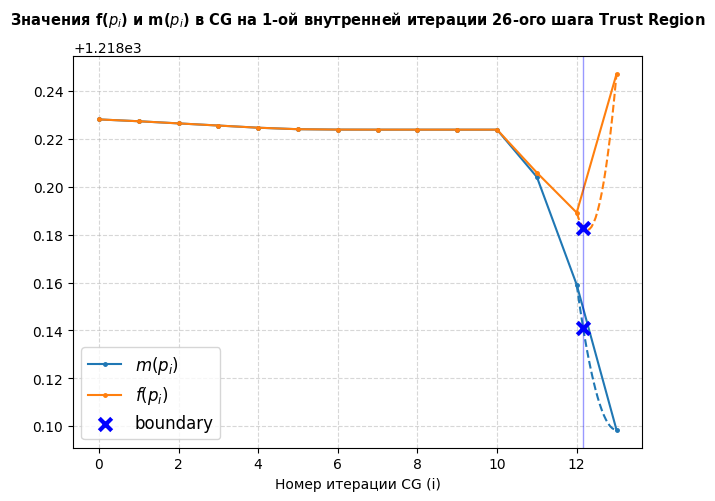

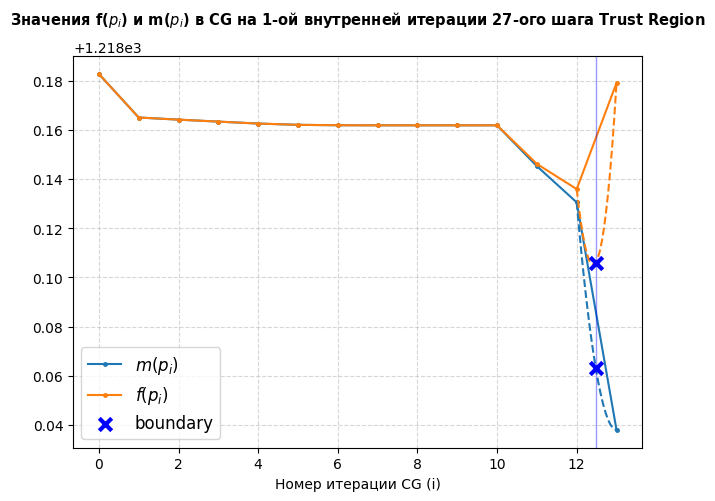

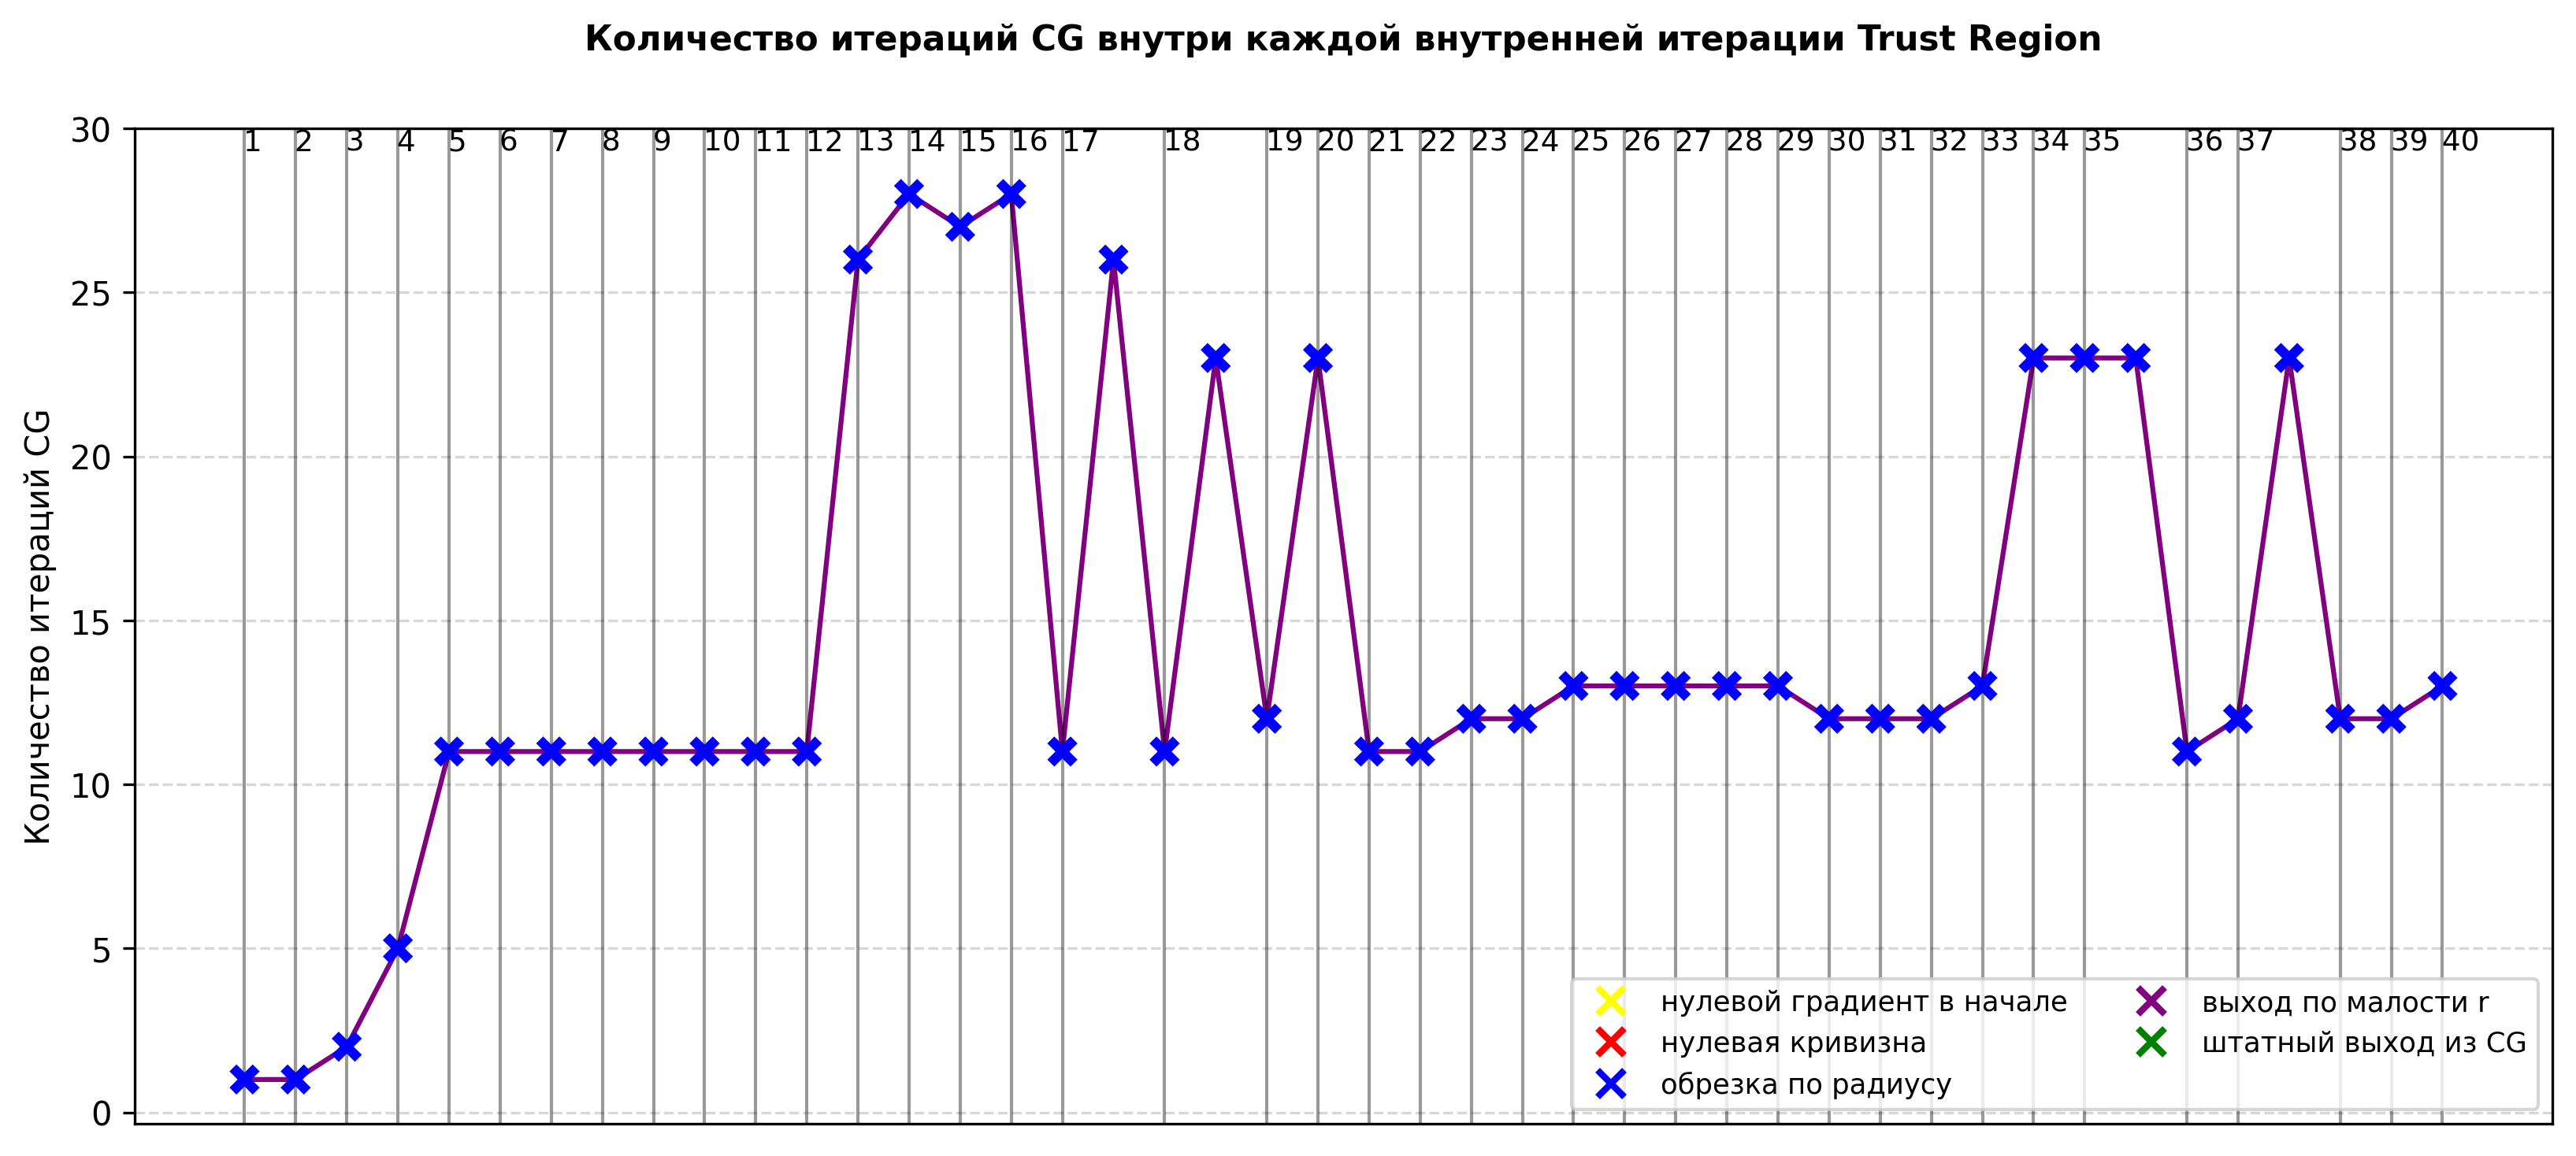


Статистика для n = 10
Итераций до сходимости:
Dogleg: 17
Море-Соренсен: 40
Адаптивный Ньютон: 16
Стейхауг-Тойнт: 40

Значение функции невязки в точке решения:
Dogleg: 3.81e-19
Море-Соренсен: 3.26e+01
Адаптивный Ньютон: 3.80e-19
Стейхауг-Тойнт: 1.22e+03



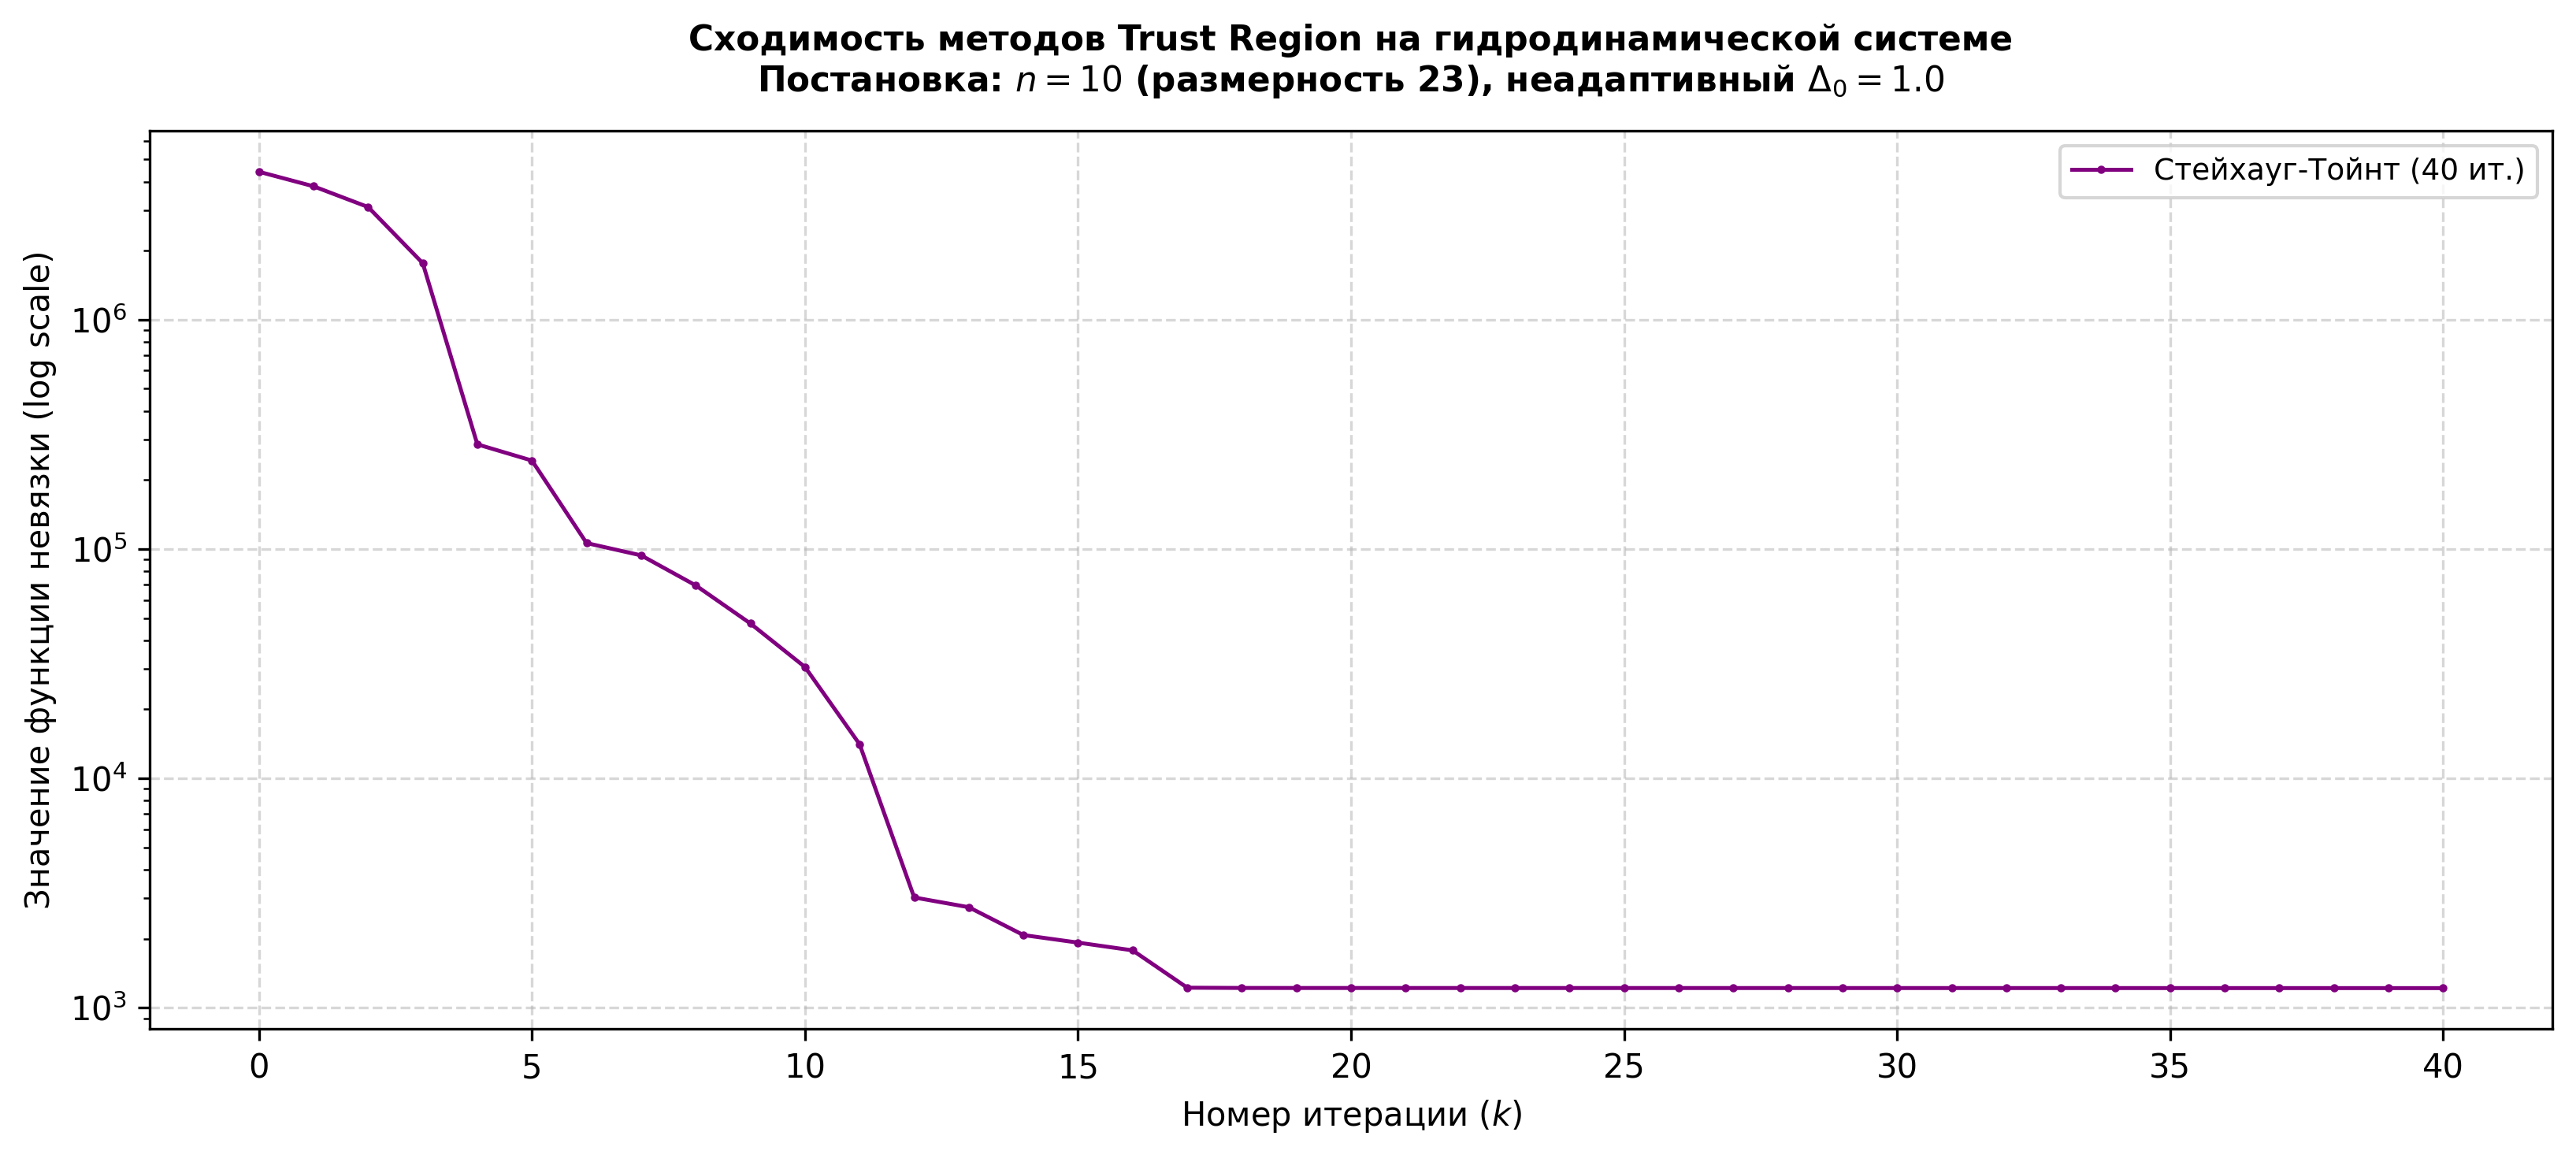

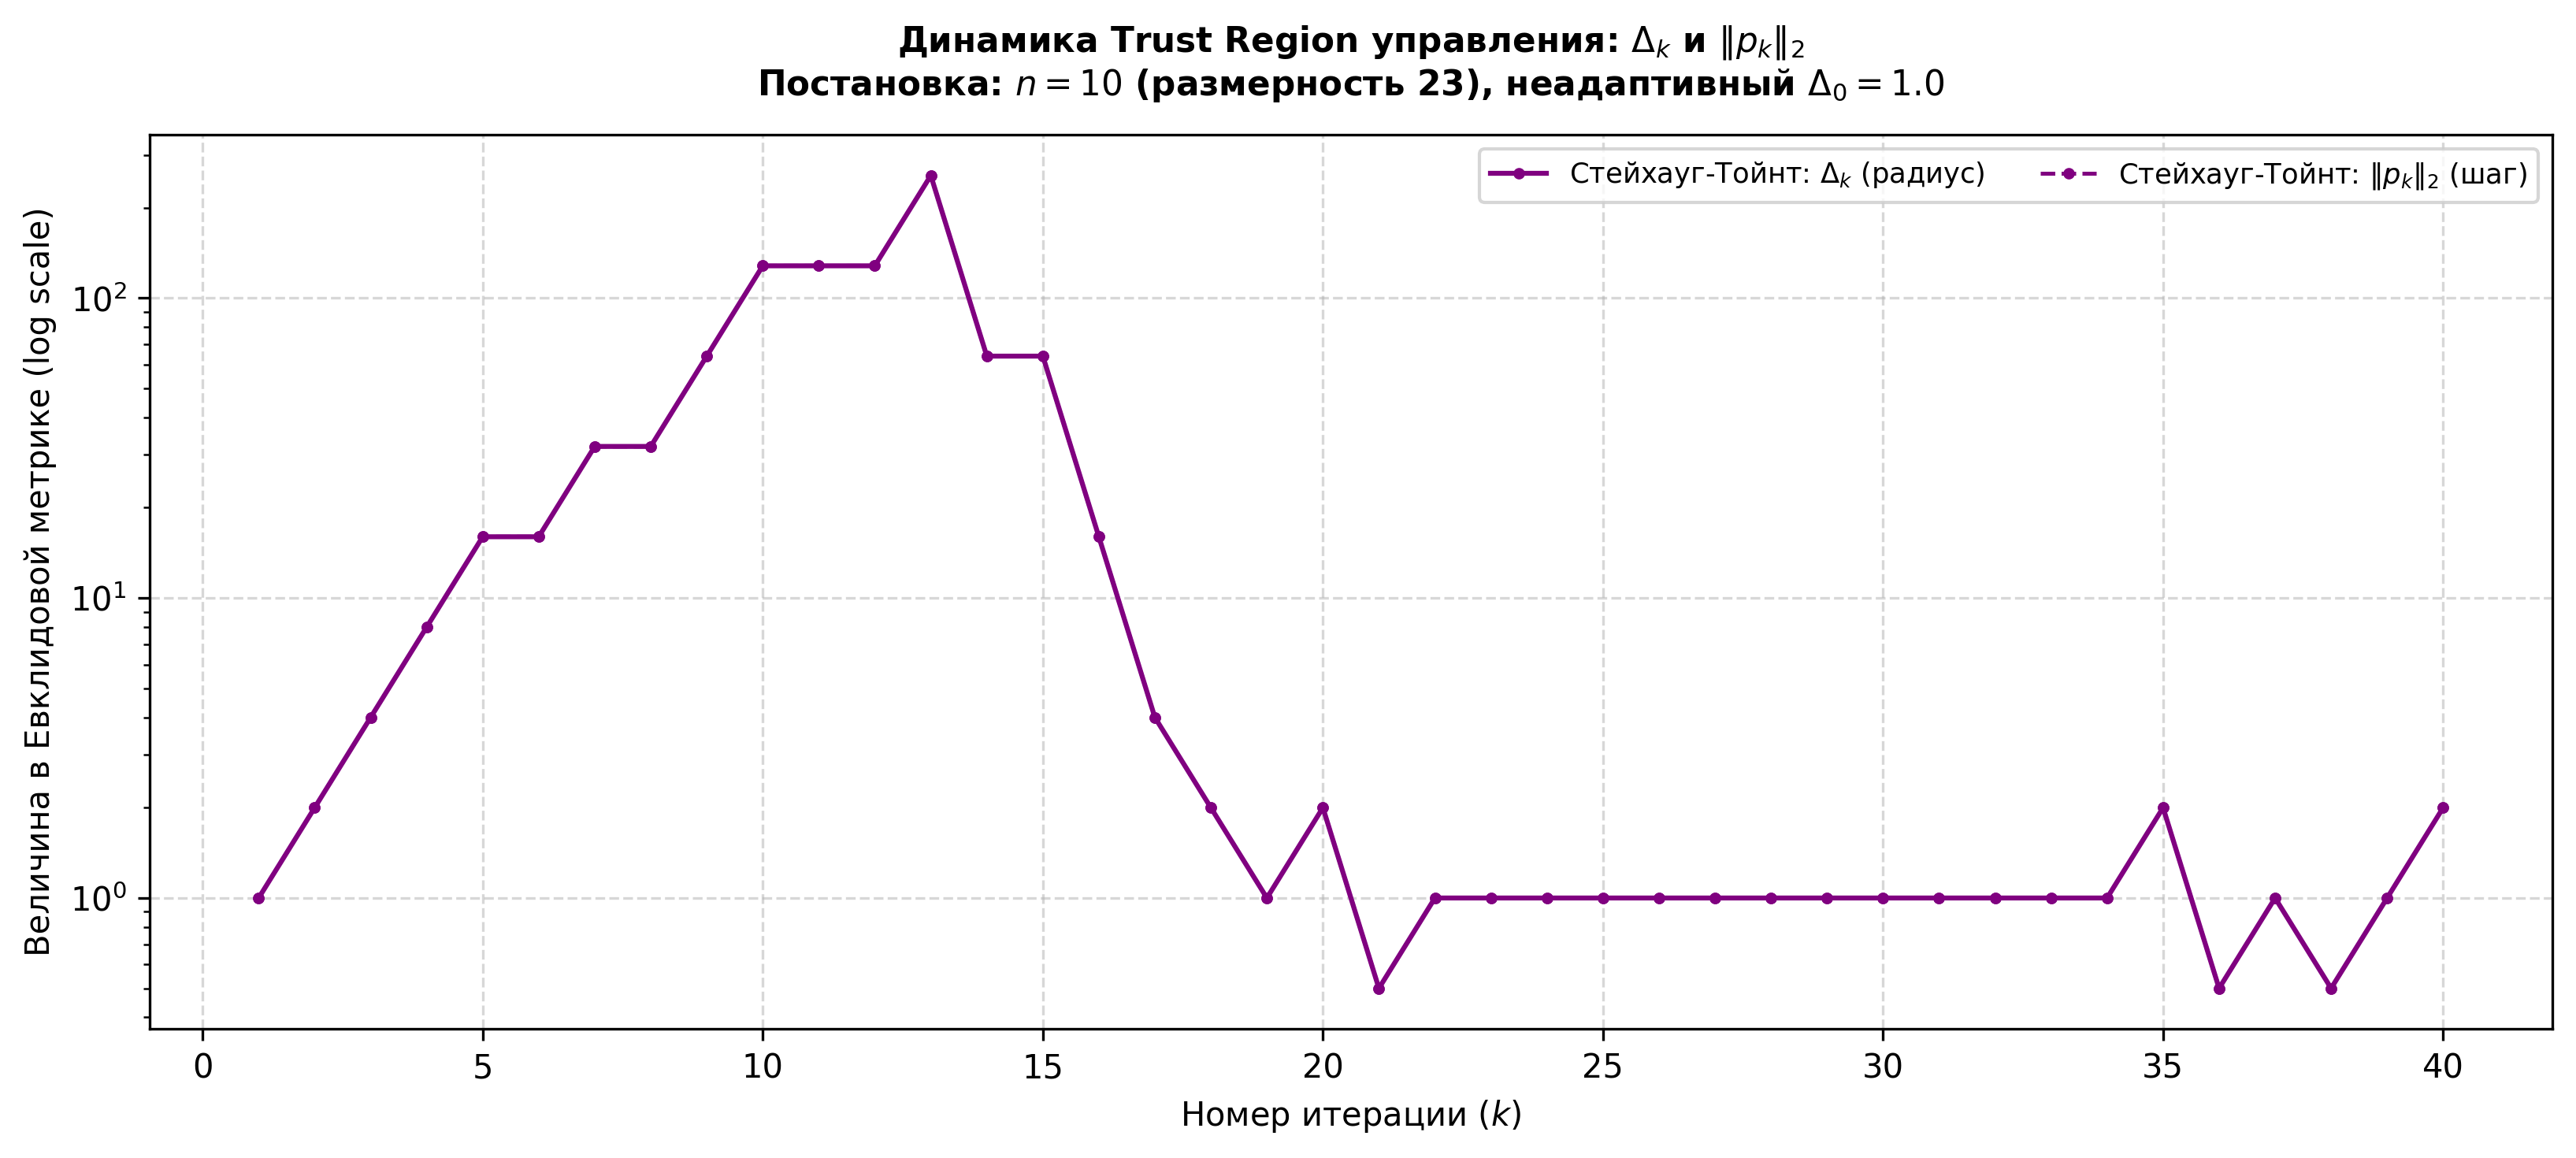

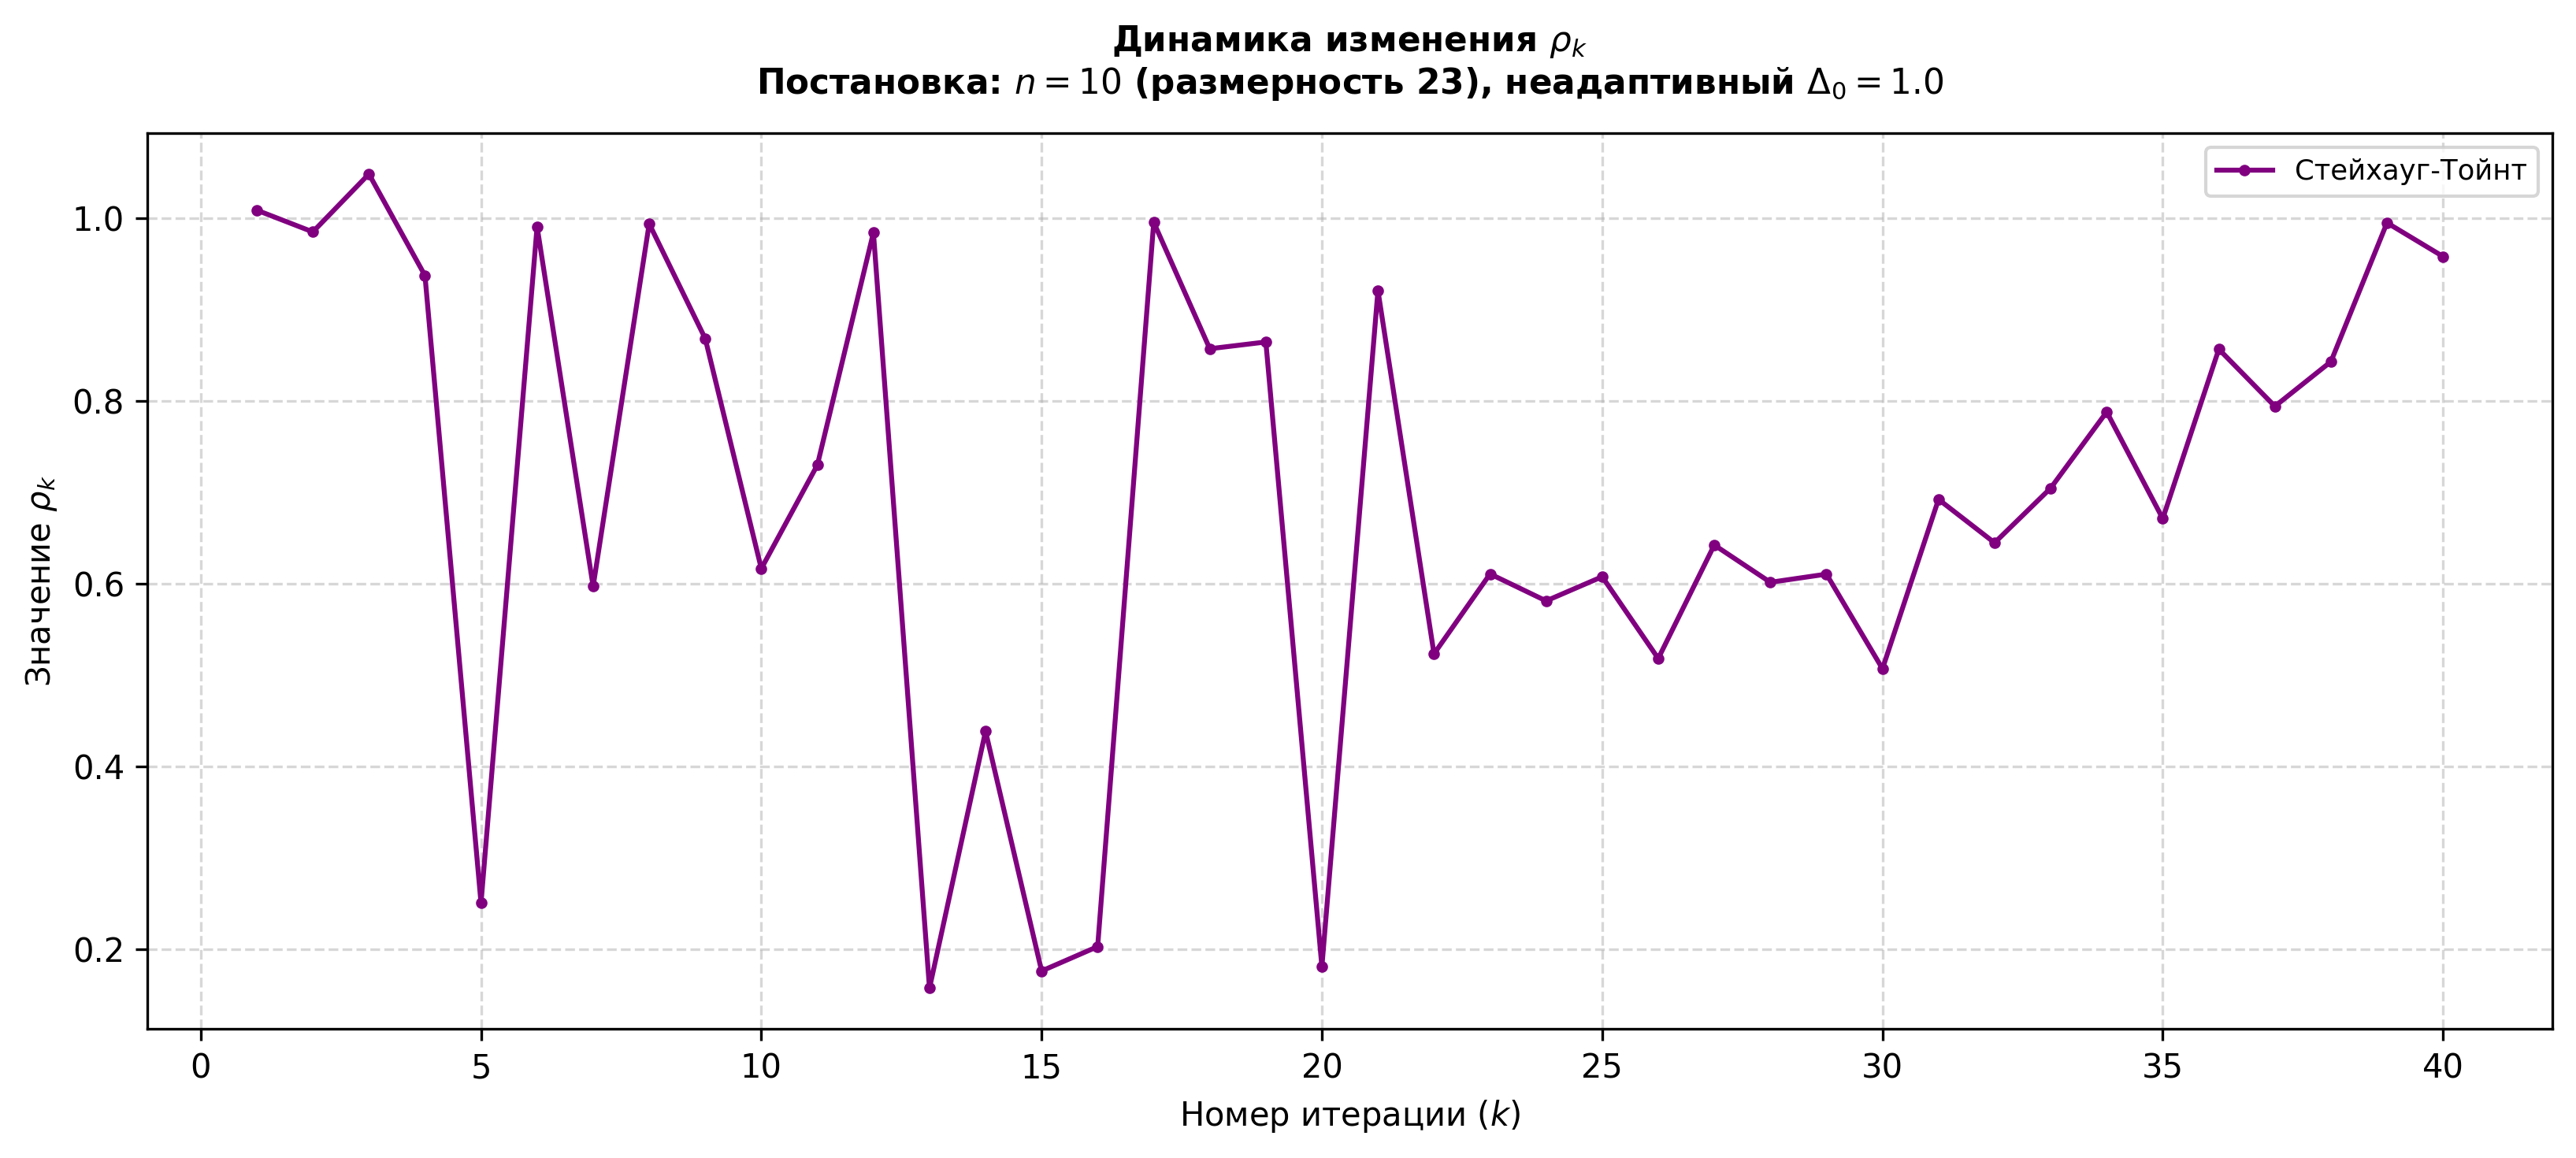

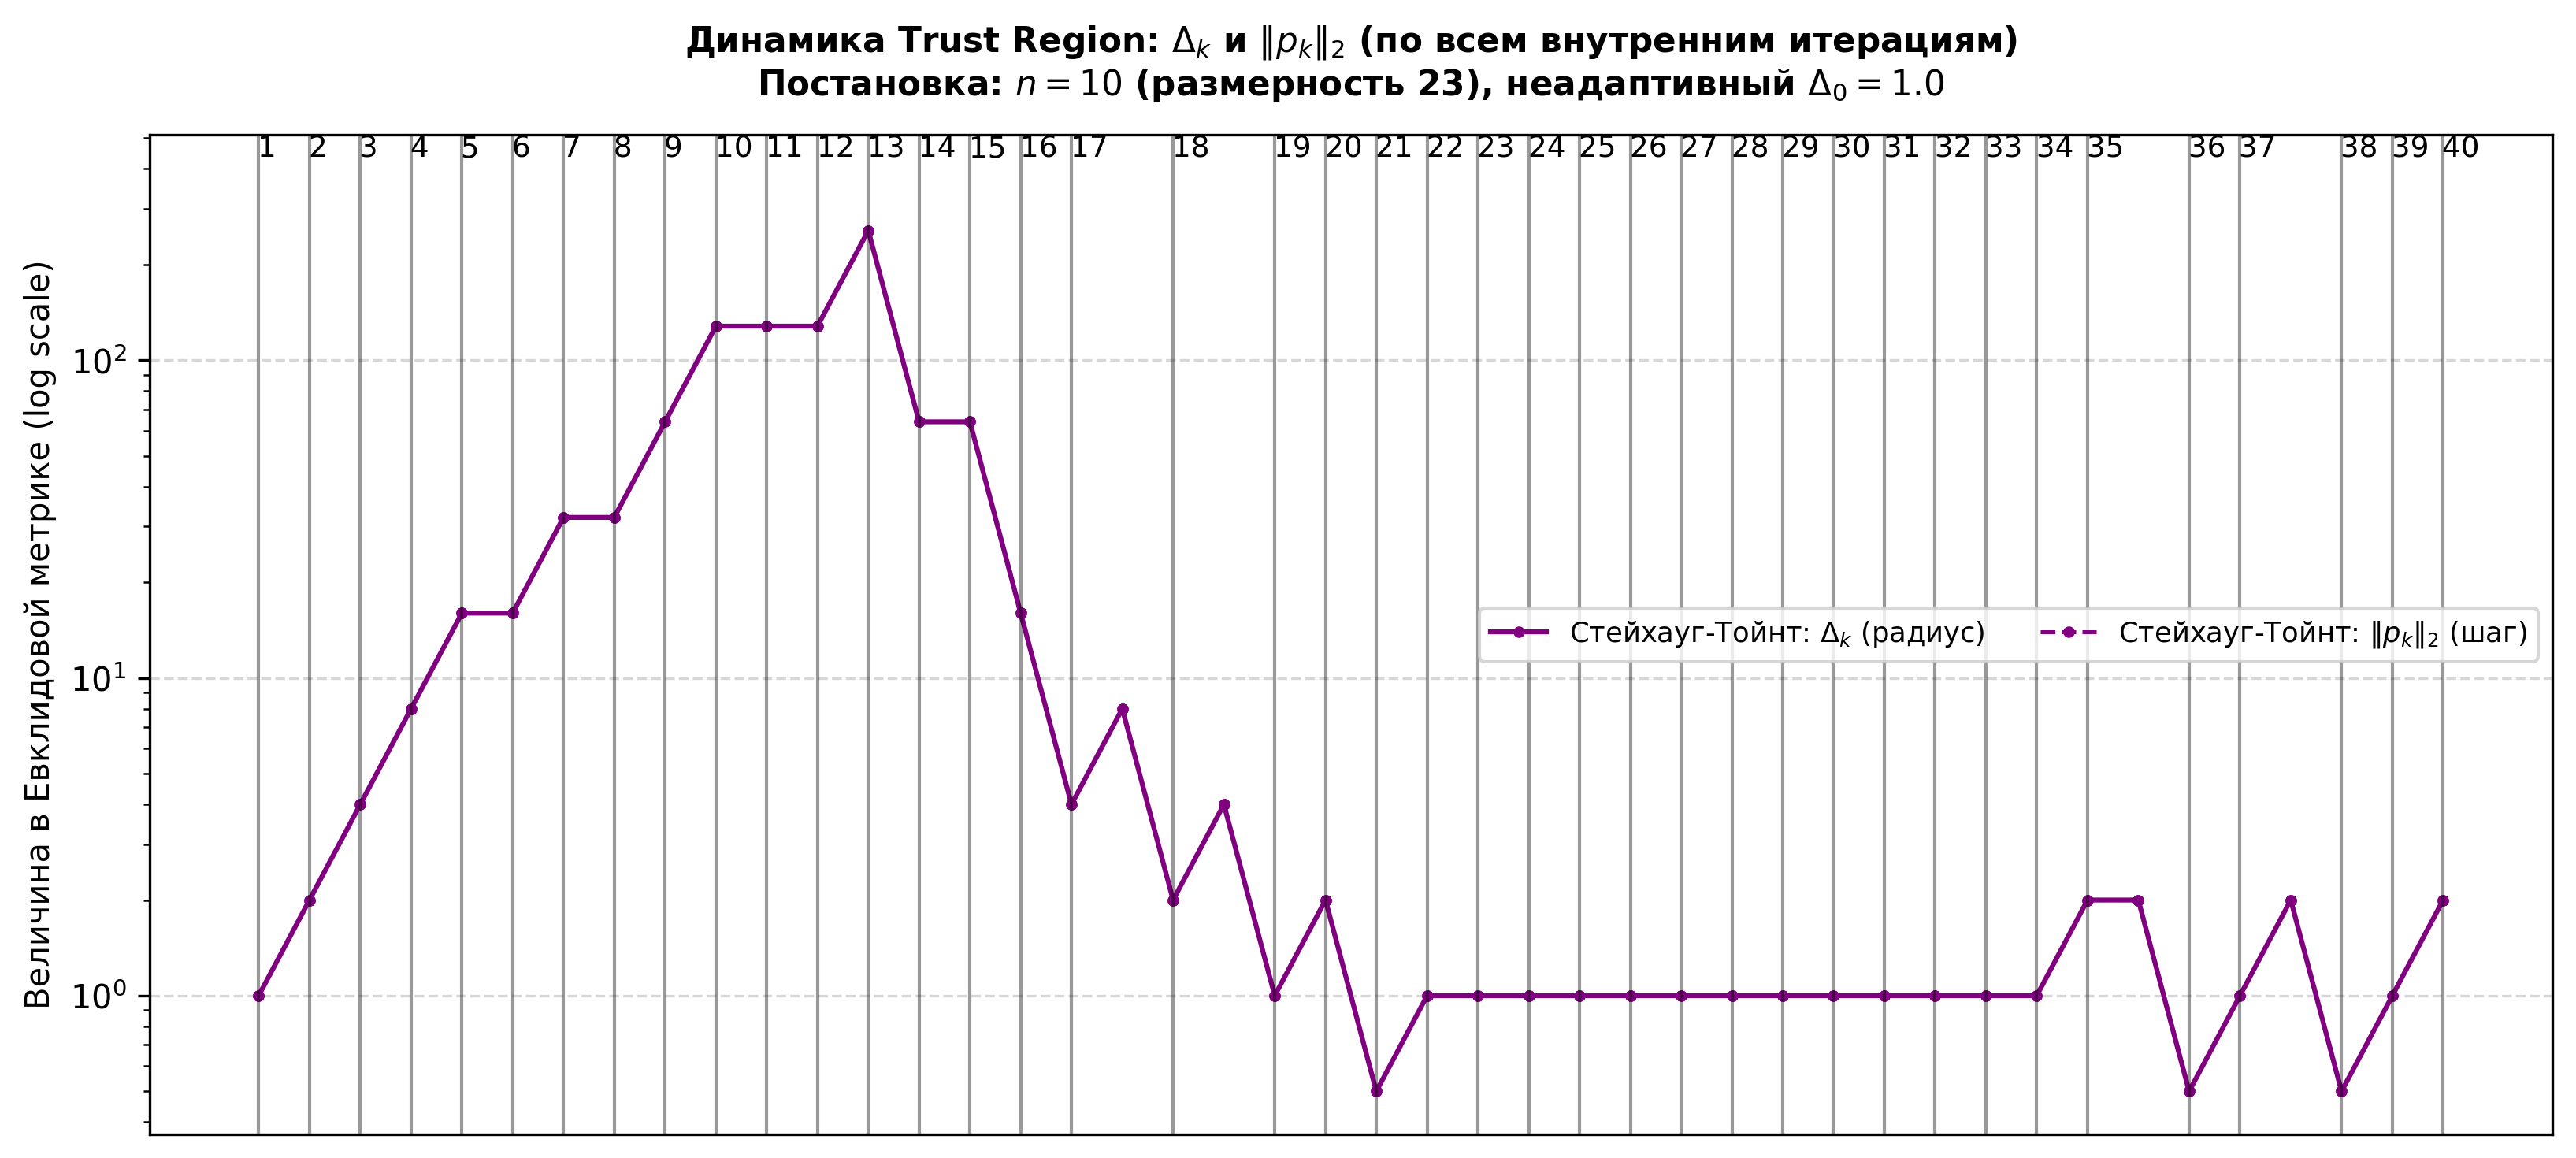

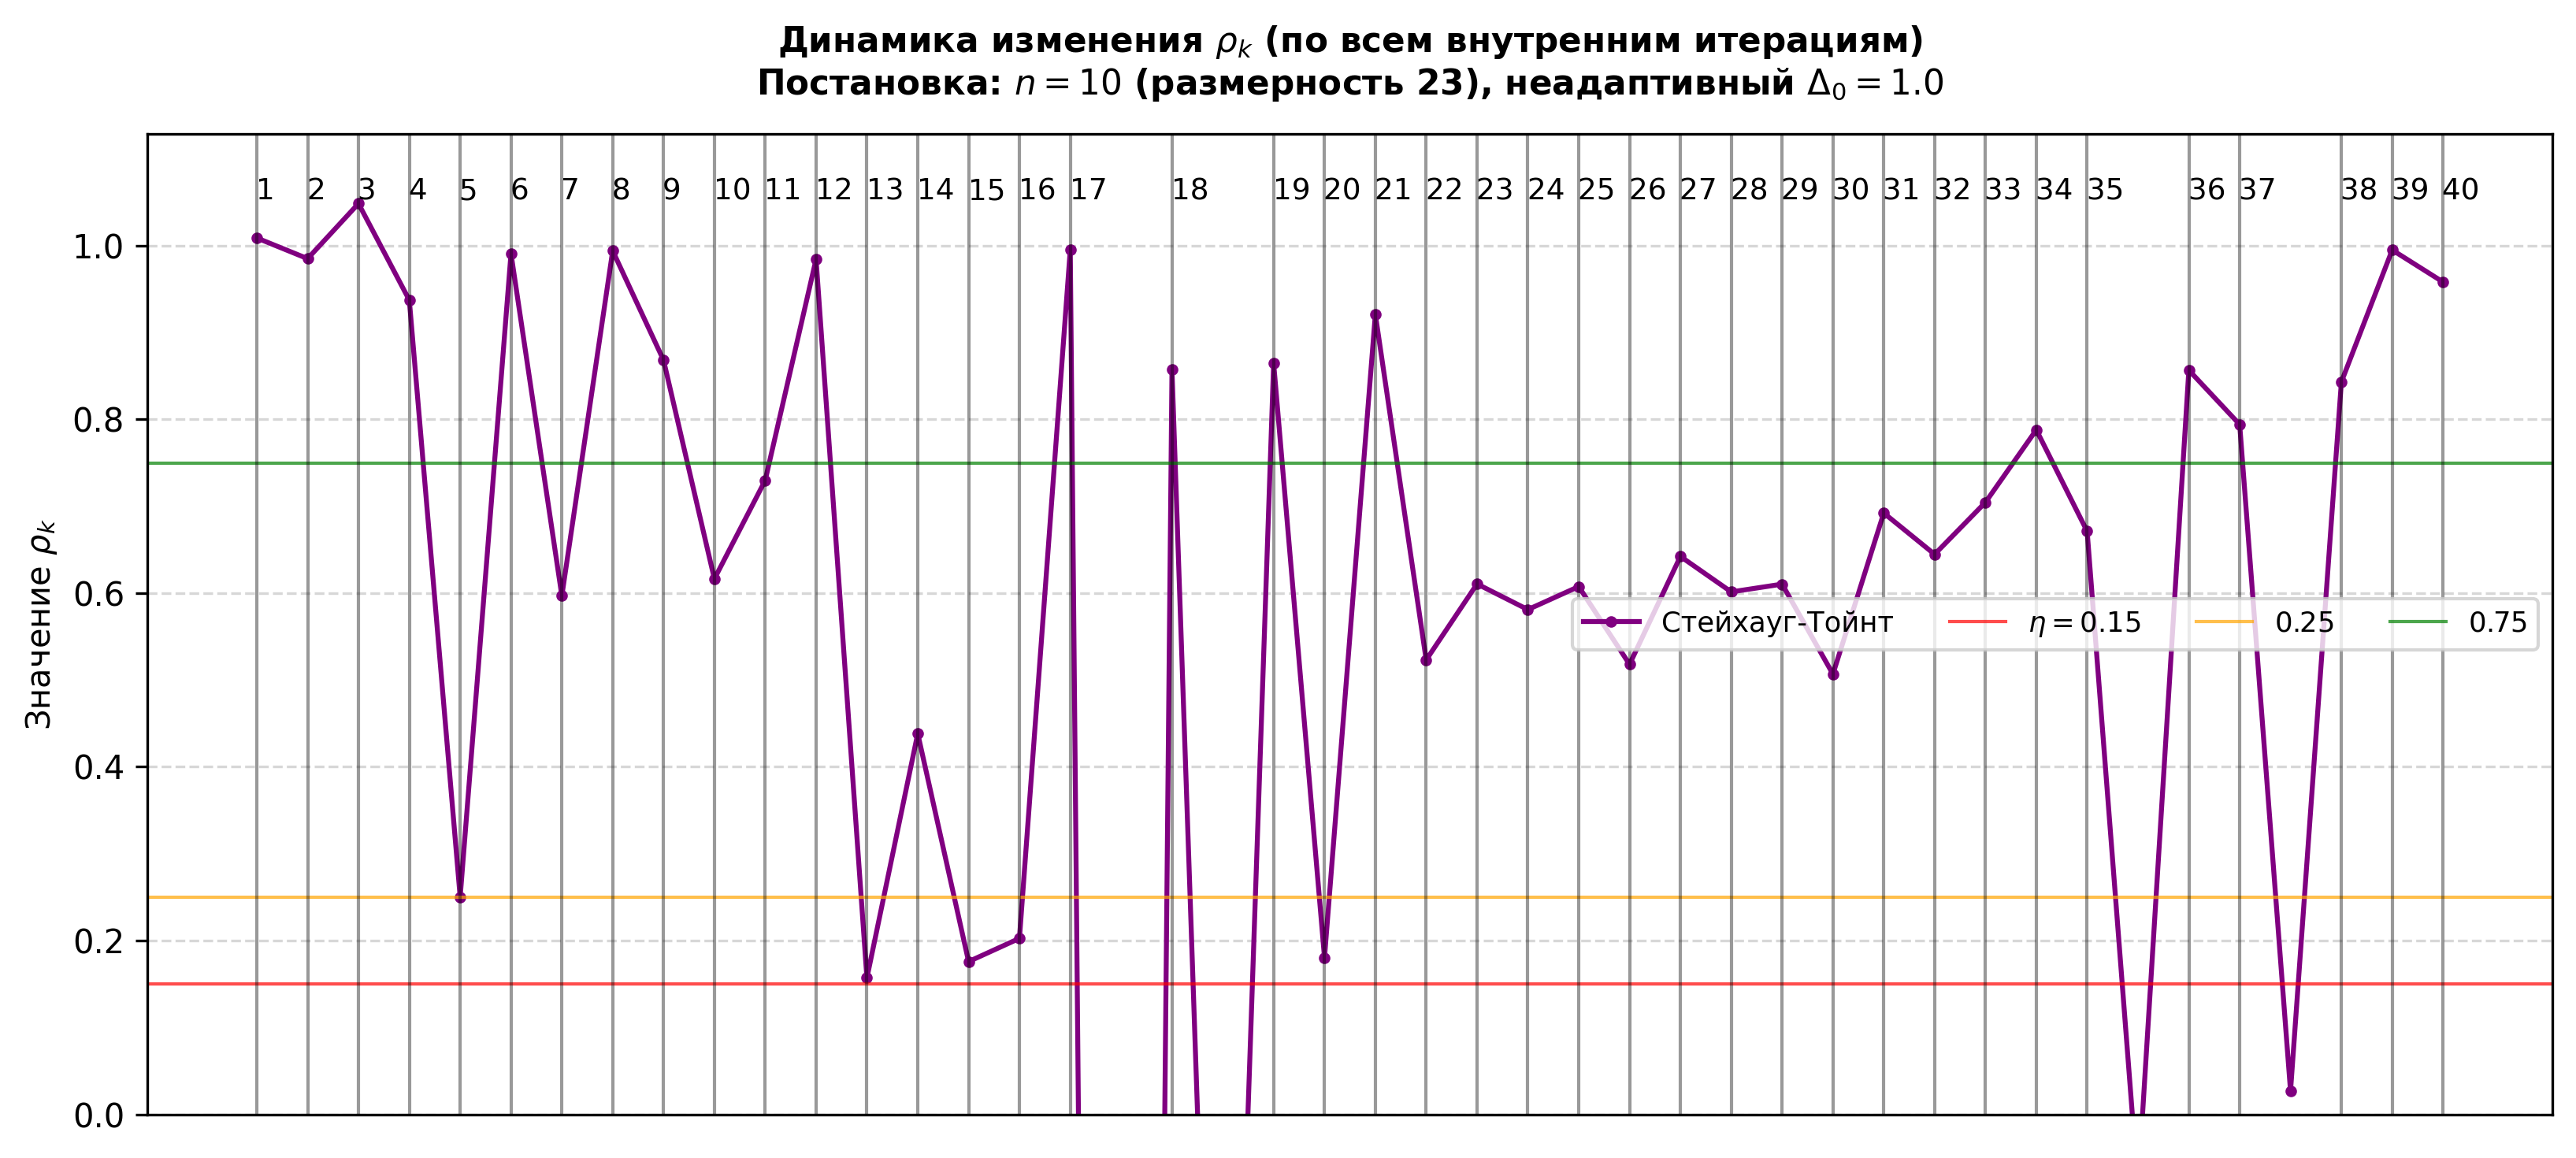

In [6]:
import numpy as np
import matplotlib.pyplot as plt

n = 10
sys = HydrodynamicsSystem(n=n, p_in=5e6, v_in=10.0) 

p_init = np.full(sys.n + 2, sys.p_in)
v_init = np.full(sys.n + 1, sys.v_in)
x0 = np.concatenate([p_init, v_init])

max_delta = 1e+6
tol_crit = 1e-6
max_it = 40

delta_fixed = 1.0

r_0 = sys.r_sys(x0)
J_0 = sys.J_sys(x0)
p_newton = np.linalg.solve(J_0, -r_0)
delta_adaptive = np.linalg.norm(p_newton)


x_dog, hist_dog, d_dog, p_norms_dog = dogleg_sys_minimization_history(
    sys.r_sys, sys.J_sys, x0, f_scalar=sys.f_sys,
    initial_delta=delta_fixed, 
    max_delta=max_delta, tol=tol_crit, max_iter=max_it
)

x_ms, hist_ms, d_ms, p_norms_ms = exact_tr_sys_minimization_history(
    sys.r_sys, sys.J_sys, x0, f_scalar=sys.f_sys,
    initial_delta=delta_fixed, 
    max_delta=max_delta, tol=tol_crit, max_iter=max_it
)

x_an, hist_an, d_an, p_norms_an = adaptive_newton_sys_minimization_history(
    sys.r_sys, sys.J_sys, x0, f_scalar=sys.f_sys,
    initial_delta=delta_fixed, 
    max_delta=max_delta, tol=tol_crit, max_iter=max_it
)

x_cg, hist_cg, d_cg, p_norms_cg, rho_cg, p_norm_all_cg, delta_all_cg, rho_all_cg = steihaug_cg_tr_sys_minimization_history(
    sys.r_sys, sys.J_sys, x0, f_scalar=sys.f_sys,
    initial_delta=delta_fixed, 
    max_delta=max_delta, tol=tol_crit, max_iter=max_it
)

print(f"\nСтатистика для n = {n}")
print(f"Итераций до сходимости:")
print(f"Dogleg: {len(hist_dog) - 1}")
print(f"Море-Соренсен: {len(hist_ms) - 1}")
print(f"Адаптивный Ньютон: {len(hist_an) - 1}")
print(f"Стейхауг-Тойнт: {len(hist_cg) - 1}\n")
print(f"Значение функции невязки в точке решения:")
print(f"Dogleg: {sys.f_sys(x_dog):.2e}")
print(f"Море-Соренсен: {sys.f_sys(x_ms):.2e}")
print(f"Адаптивный Ньютон: {sys.f_sys(x_an):.2e}")
print(f"Стейхауг-Тойнт: {sys.f_sys(x_cg):.2e}\n")


f_vals_dog = [sys.f_sys(pt) for pt in hist_dog]
f_vals_ms  = [sys.f_sys(pt) for pt in hist_ms]
f_vals_an  = [sys.f_sys(pt) for pt in hist_an]
f_vals_cg  = [sys.f_sys(pt) for pt in hist_cg]

####################################################################################################################### изменение невязки
plt.figure(figsize=(11, 5), dpi=300)

# plt.plot(np.arange(len(f_vals_dog)), f_vals_dog, '-r.', markersize=2, linewidth=1.2,
#          label=f'Dogleg ({len(f_vals_dog)-1} ит.)')
# plt.plot(np.arange(len(f_vals_ms)), f_vals_ms, '-b.', markersize=3, linewidth=1.2,
#          label=f'Море-Соренсен ({len(f_vals_ms)-1} ит.)')
# plt.plot(np.arange(len(f_vals_an)), f_vals_an, '-g.', markersize=3, linewidth=1.2,
#          label=f'Адаптивный Ньютон ({len(f_vals_an)-1} ит.)')
plt.plot(np.arange(len(f_vals_cg)), f_vals_cg, color='purple', marker='.', markersize=3, linewidth=1.2,
         label=f'Стейхауг-Тойнт ({len(f_vals_cg)-1} ит.)')

plt.yscale('log')
# plt.xscale('log')
plt.title(f"Сходимость методов Trust Region на гидродинамической системе\n"
          f"Постановка: $n = {n}$ (размерность {sys.size}), неадаптивный $\Delta_0 = {delta_fixed}$", 
          fontsize=10.5, fontweight='bold', pad=12)
plt.xlabel('Номер итерации ($k$)', fontsize=10)
plt.ylabel('Значение функции невязки (log scale)', fontsize=10)
plt.legend(loc='best', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

####################################################################################################################### управление дельта и норма p
plt.figure(figsize=(11, 5), dpi=300)

# #Dogleg
# plt.plot(np.arange(1, len(d_dog) + 1), d_dog, '-r', marker='.', markersize=5, linewidth=1.5, label=r'Dogleg: $\Delta_k$ (радиус)')
# plt.plot(np.arange(1, len(p_norms_dog) + 1), p_norms_dog, '--r', linewidth=1.2, label=r'Dogleg: $\|p_k\|_2$ (шаг)')

# #Море-Соренсен
# plt.plot(np.arange(1, len(d_ms) + 1), d_ms, '-b', marker='.', markersize=5, linewidth=1.5, label=r'Море-Соренсен: $\Delta_k$ (радиус)')
# plt.plot(np.arange(1, len(p_norms_ms) + 1), p_norms_ms, '--b', linewidth=1.2, label=r'Море-Соренсен: $\|p_k\|_2$ (шаг)')

# #Адаптивный Ньютон
# plt.plot(np.arange(1, len(d_an) + 1), d_an, '-g', marker='.', markersize=5, linewidth=1.5, label=r'Адаптивный Ньютон: $\Delta_k$ (радиус)')
# plt.plot(np.arange(1, len(p_norms_an) + 1), p_norms_an, '--g', linewidth=1.2, label=r'Адаптивный Ньютон: $\|p_k\|_2$ (шаг)')

#Стейхуаг-Тойнт
plt.plot(np.arange(1, len(d_cg) + 1), d_cg, color='purple', linestyle='-', marker='.', markersize=5, 
         linewidth=1.5, label='Стейхауг-Тойнт: $\Delta_k$ (радиус)')
plt.plot(np.arange(1, len(p_norms_cg) + 1), p_norms_cg, color='purple', marker='.', markersize=5, 
         linestyle='--', linewidth=1.2, label='Стейхауг-Тойнт: $\|p_k\|_2$ (шаг)')

plt.yscale('log')
# plt.xscale('log')
plt.title(f"Динамика Trust Region управления: $\Delta_k$ и $\|p_k\|_2$\n"
          f"Постановка: $n = {n}$ (размерность {sys.size}), неадаптивный $\Delta_0 = {delta_fixed}$", 
          fontsize=10.5, fontweight='bold', pad=12)
plt.xlabel('Номер итерации ($k$)', fontsize=10)
plt.ylabel('Величина в Евклидовой метрике (log scale)', fontsize=10)
plt.legend(loc='best', fontsize=8.5, ncol=4)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

####################################################################################################################### рисуем принятые ро
plt.figure(figsize=(11, 5), dpi=300)

# #Dogleg
# plt.plot(np.arange(1, len(d_dog) + 1), d_dog, '-r', linewidth=1.5, label=r'Dogleg: $\Delta_k$ (радиус)')
# plt.plot(np.arange(1, len(p_norms_dog) + 1), p_norms_dog, '--r', linewidth=1.2, label=r'Dogleg: $\|p_k\|_2$ (шаг)')

# #Море-Соренсен
# plt.plot(np.arange(1, len(d_ms) + 1), d_ms, '-b', linewidth=1.5, label=r'Море-Соренсен: $\Delta_k$ (радиус)')
# plt.plot(np.arange(1, len(p_norms_ms) + 1), p_norms_ms, '--b', linewidth=1.2, label=r'Море-Соренсен: $\|p_k\|_2$ (шаг)')

# #Адаптивный Ньютон
# plt.plot(np.arange(1, len(d_an) + 1), d_an, '-g', linewidth=1.5, label=r'Адаптивный Ньютон: $\Delta_k$ (радиус)')
# plt.plot(np.arange(1, len(p_norms_an) + 1), p_norms_an, '--g', linewidth=1.2, label=r'Адаптивный Ньютон: $\|p_k\|_2$ (шаг)')

#Стейхуаг-Тойнт
plt.plot(np.arange(1, len(rho_cg) + 1), rho_cg, color='purple', linestyle='-', marker='.', markersize=5,
         linewidth=1.5, label=r'Стейхауг-Тойнт')
# plt.plot(np.arange(1, len(rho_cg) + 1), [0.15] * len(rho_cg), color='r', linestyle='-', linewidth=1.5)
# plt.plot(np.arange(1, len(rho_cg) + 1), [0.25] * len(rho_cg), color='r', linestyle='-', linewidth=1.5)
# plt.plot(np.arange(1, len(rho_cg) + 1), [0.75] * len(rho_cg), color='r', linestyle='-', linewidth=1.5)




# plt.yscale('log')
# plt.xscale('log')
plt.title(r"Динамика изменения $\rho_k$"f"\n"
          f"Постановка: $n = {n}$ (размерность {sys.size}), неадаптивный $\Delta_0 = {delta_fixed}$", 
          fontsize=10.5, fontweight='bold', pad=12)
plt.xlabel('Номер итерации ($k$)', fontsize=10)
plt.ylabel(r'Значение $\rho_k$', fontsize=10)
plt.legend(loc='best', fontsize=8.5, ncol=4)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

####################################################################################################################### рисуем все дельты и нормы p (по шагам, с разделителями итераций)
plt.figure(figsize=(11, 5), dpi=300)

delta_all_cg_plot = [val for sublist in delta_all_cg for val in sublist]
p_norm_all_cg_plot = [val for sublist in p_norm_all_cg for val in sublist]

x_plot = np.arange(1, len(p_norm_all_cg_plot) + 1)

plt.plot(x_plot, delta_all_cg_plot, color='purple', linestyle='-', marker='.', markersize=5, 
         linewidth=1.5, label=r'Стейхауг-Тойнт: $\Delta_k$ (радиус)')
plt.plot(x_plot, p_norm_all_cg_plot, color='purple', marker='.', markersize=5, 
         linestyle='--', linewidth=1.2, label=r'Стейхауг-Тойнт: $\|p_k\|_2$ (шаг)')

# считаем границы внешних итераций
boundaries = np.cumsum([len(r) for r in rho_all_cg])

# задаем отступ сверху для логарифмической шкалы
y_max = max(max(delta_all_cg_plot), max(p_norm_all_cg_plot)) * 2.0

# 5. Рисуем разделители и номера итераций
for k, b_idx in enumerate(boundaries, start=1):
    plt.axvline(b_idx, color='black', linestyle='-', linewidth=1.0, alpha=0.4)
    plt.text(b_idx-0.2, y_max, f' {k}', color='black', fontsize=9, ha='left', va='top')

plt.xticks([])
plt.xlabel('')
plt.yscale('log')
plt.ylim(top=y_max)

plt.title(r"Динамика Trust Region: $\Delta_k$ и $\|p_k\|_2$ (по всем внутренним итерациям)" "\n"
          f"Постановка: $n = {n}$ (размерность {sys.size}), неадаптивный $\Delta_0 = {delta_fixed}$", 
          fontsize=10.5, fontweight='bold', pad=12)
plt.ylabel(r'Величина в Евклидовой метрике (log scale)', fontsize=10)
plt.legend(loc='best', fontsize=8.5, ncol=2)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


####################################################################################################################### рисуем все ро (по шагам, с разделителями итераций)
plt.figure(figsize=(11, 5), dpi=300)

y_plot = []
for rhos in rho_all_cg:
    y_plot.extend(rhos)

x_plot = np.arange(1, len(y_plot) + 1)

plt.plot(x_plot, y_plot, color='purple', marker='.', markersize=5, linewidth=1.5, label=r'Стейхауг-Тойнт')

plt.axhline(0.15, color='red',    linestyle='-', linewidth=1.0, alpha=0.7, label=r'$\eta=0.15$')
plt.axhline(0.25, color='orange', linestyle='-', linewidth=1.0, alpha=0.7, label=r'$0.25$')
plt.axhline(0.75, color='green',  linestyle='-', linewidth=1.0, alpha=0.7, label=r'$0.75$')


boundaries = np.cumsum([len(r) for r in rho_all_cg])

y_max = max(max(y_plot), 1.0) + 0.03

for k, b_idx in enumerate(boundaries, start=1):
    plt.axvline(b_idx, color='black', linestyle='-', linewidth=1.0, alpha=0.4)
    plt.text(b_idx-0.2, y_max, f' {k}', color='black', fontsize=9, ha='left', va='top')

plt.xticks([])
plt.xlabel('')
plt.ylim(bottom=0, top=y_max + 0.05)

plt.title(r"Динамика изменения $\rho_k$ (по всем внутренним итерациям)" "\n"
          f"Постановка: $n = {n}$ (размерность {sys.size}), неадаптивный $\Delta_0 = {delta_fixed}$",
          fontsize=10.5, fontweight='bold', pad=12)
plt.ylabel(r'Значение $\rho_k$', fontsize=10)
plt.legend(loc='best', fontsize=8.5, ncol=4)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
